Homework 10: Improving RAG with Reranking, Chunking, and Conversational Memory

In [1]:
import sys
import platform

print("=" * 60)
print("ENVIRONMENT CHECK")
print("=" * 60)

print("Python version:", sys.version.split()[0])
print("Operating system:", platform.system())

try:
    import torch

    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    print("Selected device:", DEVICE)

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))

except ImportError:
    DEVICE = "cpu"
    print("PyTorch is not currently installed.")
    print("Selected device:", DEVICE)

print("=" * 60)

ENVIRONMENT CHECK
Python version: 3.13.16
Operating system: Linux
PyTorch version: 2.14.1+cu130
CUDA available: True
Selected device: cuda
GPU: NVIDIA L4


In [2]:
%pip install -q \
    "datasets==4.3.0" \
    "sentence-transformers==6.2.0" \
    "chromadb==1.5.9" \
    "langchain-text-splitters==1.1.3" \
    ipywidgets

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.9.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil

In [3]:
import datasets
import sentence_transformers
import chromadb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets

from langchain_text_splitters import RecursiveCharacterTextSplitter
from importlib.metadata import version

print("=" * 60)
print("PACKAGE VERIFICATION")
print("=" * 60)

required_packages = [
    "datasets",
    "sentence-transformers",
    "chromadb",
    "langchain-text-splitters",
    "pandas",
    "numpy"
]

for package in required_packages:
    print(f"{package:30s}: {version(package)}")

print("\nAll required libraries imported successfully.")
print("=" * 60)

PACKAGE VERIFICATION
datasets                      : 4.3.0
sentence-transformers         : 6.2.0
chromadb                      : 1.5.9
langchain-text-splitters      : 1.1.3
pandas                        : 2.2.3
numpy                         : 2.4.6

All required libraries imported successfully.


## Task 1: Dataset Loading and Preprocessing

### 1.1 Load the Required Dataset

The assignment requires the non-pre-chunked `ccdv/arxiv-summarization` dataset from Hugging Face.

This notebook uses:

- Configuration: `document`
- Split: `train`
- Number of documents: first 100

Streaming is used so that the complete dataset does not need to be downloaded.

In [4]:
from datasets import load_dataset
from itertools import islice
import pandas as pd

DATASET_NAME = "ccdv/arxiv-summarization"
DATASET_CONFIG = "document"
DATASET_SPLIT = "train"
NUM_DOCUMENTS = 100

print("=" * 60)
print("LOADING THE ARXIV SUMMARIZATION DATASET")
print("=" * 60)

print("Dataset:", DATASET_NAME)
print("Configuration:", DATASET_CONFIG)
print("Split:", DATASET_SPLIT)
print("Requested documents:", NUM_DOCUMENTS)

dataset_stream = load_dataset(
    DATASET_NAME,
    DATASET_CONFIG,
    split=DATASET_SPLIT,
    streaming=True
)

documents = list(islice(dataset_stream, NUM_DOCUMENTS))

if len(documents) != NUM_DOCUMENTS:
    raise ValueError(
        f"Expected {NUM_DOCUMENTS} documents, "
        f"but loaded {len(documents)}."
    )

documents_df = pd.DataFrame(documents)

documents_df.insert(
    0,
    "document_id",
    [f"doc_{index:03d}" for index in range(len(documents_df))]
)

required_columns = {"article", "abstract"}

if not required_columns.issubset(documents_df.columns):
    raise ValueError(
        f"Required columns are missing. "
        f"Available columns: {documents_df.columns.tolist()}"
    )

print("\nDataset loaded successfully.")
print("Number of documents:", len(documents_df))
print("Columns:", documents_df.columns.tolist())
print("Unique document IDs:", documents_df["document_id"].nunique())
print("Missing article texts:", documents_df["article"].isna().sum())
print("Missing abstracts:", documents_df["abstract"].isna().sum())

print("\nFirst document")
print("-" * 60)
print("Document ID:", documents_df.loc[0, "document_id"])
print("Article preview:")
print(str(documents_df.loc[0, "article"])[:700])

print("\n" + "=" * 60)
print("DATASET LOADING COMPLETED")
print("=" * 60)

LOADING THE ARXIV SUMMARIZATION DATASET
Dataset: ccdv/arxiv-summarization
Configuration: document
Split: train
Requested documents: 100


README.md:   0%|          | 0.00/3.96k [00:00<?, ?B/s]


Dataset loaded successfully.
Number of documents: 100
Columns: ['document_id', 'article', 'abstract']
Unique document IDs: 100
Missing article texts: 0
Missing abstracts: 0

First document
------------------------------------------------------------
Document ID: doc_000
Article preview:
additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . it is well - known that good estimators in additive models are in general less prone to the curse of high dimensionality than good estimators in fully nonparametric models . many examples of such estimators belong to the large class of regularized kernel based methods over a reproducing kernel hilbert space @xmath0 , see e.g. @xcite . in the last years many interesting r

DATASET L

### 1.2 Dataset Exploration and Preprocessing

The article text will be cleaned before chunking.

The preprocessing procedure:

1. Converts non-string or missing values to empty strings.
2. Removes leading and trailing whitespace.
3. Replaces repeated whitespace, tabs, and line breaks with a single space.
4. Preserves scientific notation and dataset tokens such as `@xmath` and `@xcite`.
5. Checks for empty and duplicate articles.
6. Calculates document-length statistics.

In [5]:
import re
import pandas as pd

def clean_article_text(text):
    """
    Normalize whitespace while preserving the scientific content.
    """
    if not isinstance(text, str):
        return ""

    cleaned_text = text.strip()
    cleaned_text = re.sub(r"\s+", " ", cleaned_text)

    return cleaned_text


# Preserve the original DataFrame
processed_df = documents_df.copy()

# Clean the complete article text
processed_df["cleaned_article"] = (
    processed_df["article"].apply(clean_article_text)
)

# Calculate document statistics
processed_df["character_count"] = (
    processed_df["cleaned_article"].str.len()
)

processed_df["word_count"] = (
    processed_df["cleaned_article"].str.split().str.len()
)

# Data-quality checks
empty_document_count = (
    processed_df["cleaned_article"].eq("").sum()
)

duplicate_document_count = (
    processed_df["cleaned_article"].duplicated().sum()
)

missing_document_ids = (
    processed_df["document_id"].isna().sum()
)

# Validate the processed dataset
assert len(processed_df) == 100
assert processed_df["document_id"].nunique() == 100
assert missing_document_ids == 0
assert empty_document_count == 0

print("=" * 65)
print("DATASET EXPLORATION AND PREPROCESSING")
print("=" * 65)

print("Total documents:", len(processed_df))
print("Unique document IDs:", processed_df["document_id"].nunique())
print("Empty cleaned articles:", empty_document_count)
print("Duplicate cleaned articles:", duplicate_document_count)

print("\nDOCUMENT LENGTH STATISTICS")
print("-" * 65)

print(
    processed_df[
        ["character_count", "word_count"]
    ].describe().round(2).to_string()
)

print("\nFIRST FIVE DOCUMENTS")
print("-" * 65)

print(
    processed_df[
        ["document_id", "character_count", "word_count"]
    ].head().to_string(index=False)
)

print("\nCLEANED ARTICLE PREVIEW")
print("-" * 65)
print(processed_df.loc[0, "cleaned_article"][:700])

print("\n" + "=" * 65)
print("PREPROCESSING COMPLETED")
print("=" * 65)

DATASET EXPLORATION AND PREPROCESSING
Total documents: 100
Unique document IDs: 100
Empty cleaned articles: 0
Duplicate cleaned articles: 0

DOCUMENT LENGTH STATISTICS
-----------------------------------------------------------------
       character_count  word_count
count           100.00      100.00
mean          36104.50     6516.53
std           31576.78     5442.17
min            3412.00      604.00
25%           18327.00     3265.00
50%           26485.00     4847.00
75%           42704.50     8004.00
max          193142.00    33095.00

FIRST FIVE DOCUMENTS
-----------------------------------------------------------------
document_id  character_count  word_count
    doc_000            26024        4467
    doc_001            17514        3223
    doc_002            29833        5292
    doc_003            20804        3714
    doc_004            51560        9235

CLEANED ARTICLE PREVIEW
-----------------------------------------------------------------
additive models @xcite pro

### 1.3 Chunking Strategy 1: Fixed-Size Character Chunking

The first strategy divides each article into fixed-size character windows.

Configuration:

- Maximum chunk size: 1,000 characters
- Overlap: 200 characters
- Step size: 800 characters

The overlap allows neighboring chunks to share context. Fixed-size chunking is simple and predictable, but it may split sentences or ideas at arbitrary character positions.

In [6]:
import pandas as pd

FIXED_CHUNK_SIZE = 1000
FIXED_CHUNK_OVERLAP = 200


def fixed_size_chunking(
    text,
    chunk_size=FIXED_CHUNK_SIZE,
    overlap=FIXED_CHUNK_OVERLAP
):
    """
    Divide text into fixed-size overlapping character chunks.

    Returns each chunk together with its start and end positions.
    """
    if not isinstance(text, str):
        return []

    if chunk_size <= 0:
        raise ValueError("Chunk size must be positive.")

    if overlap < 0 or overlap >= chunk_size:
        raise ValueError(
            "Overlap must be nonnegative and smaller than chunk size."
        )

    chunks = []
    step_size = chunk_size - overlap

    for start_character in range(0, len(text), step_size):
        end_character = min(
            start_character + chunk_size,
            len(text)
        )

        chunk_text = text[start_character:end_character]

        if chunk_text:
            chunks.append({
                "chunk_text": chunk_text,
                "start_character": start_character,
                "end_character": end_character
            })

        if end_character == len(text):
            break

    return chunks


fixed_chunk_records = []

for _, document_row in processed_df.iterrows():

    document_id = document_row["document_id"]
    article_text = document_row["cleaned_article"]

    document_chunks = fixed_size_chunking(article_text)

    for chunk_index, chunk in enumerate(document_chunks):

        fixed_chunk_records.append({
            "chunk_id": (
                f"{document_id}_fixed_{chunk_index:04d}"
            ),
            "document_id": document_id,
            "chunk_index": chunk_index,
            "chunk_text": chunk["chunk_text"],
            "start_character": chunk["start_character"],
            "end_character": chunk["end_character"],
            "character_count": len(chunk["chunk_text"]),
            "strategy": "fixed_size"
        })


fixed_chunks_df = pd.DataFrame(fixed_chunk_records)

# Validate the fixed-size chunks
assert fixed_chunks_df["document_id"].nunique() == 100
assert fixed_chunks_df["chunk_id"].is_unique
assert fixed_chunks_df["chunk_text"].notna().all()
assert fixed_chunks_df["character_count"].gt(0).all()
assert (
    fixed_chunks_df["character_count"] <= FIXED_CHUNK_SIZE
).all()

print("=" * 65)
print("CHUNKING STRATEGY 1: FIXED-SIZE CHUNKING")
print("=" * 65)

print("Chunk size:", FIXED_CHUNK_SIZE)
print("Chunk overlap:", FIXED_CHUNK_OVERLAP)
print("Step size:", FIXED_CHUNK_SIZE - FIXED_CHUNK_OVERLAP)
print("Documents represented:", fixed_chunks_df["document_id"].nunique())
print("Total chunks generated:", len(fixed_chunks_df))
print("Unique chunk IDs:", fixed_chunks_df["chunk_id"].nunique())

print("\nCHUNK-LENGTH STATISTICS")
print("-" * 65)

print(
    fixed_chunks_df["character_count"]
    .describe()
    .round(2)
    .to_string()
)

print("\nFIRST FIVE CHUNKS")
print("-" * 65)

print(
    fixed_chunks_df[
        [
            "chunk_id",
            "document_id",
            "chunk_index",
            "start_character",
            "end_character",
            "character_count"
        ]
    ].head().to_string(index=False)
)

print("\nFIRST CHUNK PREVIEW")
print("-" * 65)
print(fixed_chunks_df.loc[0, "chunk_text"][:700])

print("\n" + "=" * 65)
print("FIXED-SIZE CHUNKING COMPLETED")
print("=" * 65)

CHUNKING STRATEGY 1: FIXED-SIZE CHUNKING
Chunk size: 1000
Chunk overlap: 200
Step size: 800
Documents represented: 100
Total chunks generated: 4536
Unique chunk IDs: 4536

CHUNK-LENGTH STATISTICS
-----------------------------------------------------------------
count    4536.00
mean      991.55
std        65.18
min       212.00
25%      1000.00
50%      1000.00
75%      1000.00
max      1000.00

FIRST FIVE CHUNKS
-----------------------------------------------------------------
          chunk_id document_id  chunk_index  start_character  end_character  character_count
doc_000_fixed_0000     doc_000            0                0           1000             1000
doc_000_fixed_0001     doc_000            1              800           1800             1000
doc_000_fixed_0002     doc_000            2             1600           2600             1000
doc_000_fixed_0003     doc_000            3             2400           3400             1000
doc_000_fixed_0004     doc_000            4         

### 1.4 Chunking Strategy 2: Recursive Character Chunking

The second strategy uses recursive character chunking.

Rather than cutting only at an exact character position, the recursive splitter attempts to preserve natural text boundaries in this order:

1. Paragraph boundaries
2. Line boundaries
3. Sentence boundaries
4. Punctuation boundaries
5. Word boundaries
6. Individual characters as a final fallback

Configuration:

- Maximum chunk size: 1,000 characters
- Requested overlap: 200 characters

This strategy should produce chunks that are more linguistically coherent than fixed-size chunking.

In [7]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
import pandas as pd

RECURSIVE_CHUNK_SIZE = 1000
RECURSIVE_CHUNK_OVERLAP = 200

recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=RECURSIVE_CHUNK_SIZE,
    chunk_overlap=RECURSIVE_CHUNK_OVERLAP,
    separators=[
        "\n\n",
        "\n",
        " . ",
        ". ",
        "? ",
        "! ",
        "; ",
        ", ",
        " ",
        ""
    ],
    length_function=len,
    keep_separator=True
)

recursive_chunk_records = []

for _, document_row in processed_df.iterrows():

    document_id = document_row["document_id"]
    article_text = document_row["cleaned_article"]

    document_chunks = recursive_splitter.split_text(
        article_text
    )

    for chunk_index, chunk_text in enumerate(document_chunks):

        recursive_chunk_records.append({
            "chunk_id": (
                f"{document_id}_recursive_{chunk_index:04d}"
            ),
            "document_id": document_id,
            "chunk_index": chunk_index,
            "chunk_text": chunk_text,
            "character_count": len(chunk_text),
            "strategy": "recursive"
        })


recursive_chunks_df = pd.DataFrame(
    recursive_chunk_records
)

# Validate the recursive chunks
assert recursive_chunks_df["document_id"].nunique() == 100
assert recursive_chunks_df["chunk_id"].is_unique
assert recursive_chunks_df["chunk_text"].notna().all()
assert recursive_chunks_df["character_count"].gt(0).all()
assert (
    recursive_chunks_df["character_count"]
    <= RECURSIVE_CHUNK_SIZE
).all()

print("=" * 65)
print("CHUNKING STRATEGY 2: RECURSIVE CHUNKING")
print("=" * 65)

print("Maximum chunk size:", RECURSIVE_CHUNK_SIZE)
print("Requested overlap:", RECURSIVE_CHUNK_OVERLAP)
print(
    "Documents represented:",
    recursive_chunks_df["document_id"].nunique()
)
print(
    "Total chunks generated:",
    len(recursive_chunks_df)
)
print(
    "Unique chunk IDs:",
    recursive_chunks_df["chunk_id"].nunique()
)

print("\nCHUNK-LENGTH STATISTICS")
print("-" * 65)

print(
    recursive_chunks_df["character_count"]
    .describe()
    .round(2)
    .to_string()
)

print("\nFIRST FIVE CHUNKS")
print("-" * 65)

print(
    recursive_chunks_df[
        [
            "chunk_id",
            "document_id",
            "chunk_index",
            "character_count"
        ]
    ].head().to_string(index=False)
)

print("\nFIRST CHUNK PREVIEW")
print("-" * 65)
print(
    recursive_chunks_df.loc[0, "chunk_text"][:700]
)

print("\n" + "=" * 65)
print("RECURSIVE CHUNKING COMPLETED")
print("=" * 65)

CHUNKING STRATEGY 2: RECURSIVE CHUNKING
Maximum chunk size: 1000
Requested overlap: 200
Documents represented: 100
Total chunks generated: 4660
Unique chunk IDs: 4660

CHUNK-LENGTH STATISTICS
-----------------------------------------------------------------
count    4660.00
mean      873.91
std       145.51
min         9.00
25%       845.75
50%       916.00
75%       962.00
max      1000.00

FIRST FIVE CHUNKS
-----------------------------------------------------------------
              chunk_id document_id  chunk_index  character_count
doc_000_recursive_0000     doc_000            0              978
doc_000_recursive_0001     doc_000            1              917
doc_000_recursive_0002     doc_000            2              866
doc_000_recursive_0003     doc_000            3              968
doc_000_recursive_0004     doc_000            4              910

FIRST CHUNK PREVIEW
-----------------------------------------------------------------
additive models @xcite provide an important 

### 1.5 Structural Comparison of the Chunking Strategies

Before retrieval, the two chunking strategies are compared using:

- total number of chunks;
- average chunk length;
- median chunk length;
- minimum and maximum lengths;
- number of very short chunks;
- chunk-length distributions.

This is a structural comparison only. Retrieval-quality differences will be evaluated later using relevance judgments and retrieval metrics.

STRUCTURAL COMPARISON OF CHUNKING STRATEGIES
Chunking Strategy  Total Chunks  Mean Length  Median Length  Minimum Length  Maximum Length  Chunks Under 200 Characters
       Fixed-Size          4536       991.55         1000.0             212            1000                            0
        Recursive          4660       873.91          916.0               9            1000                           36


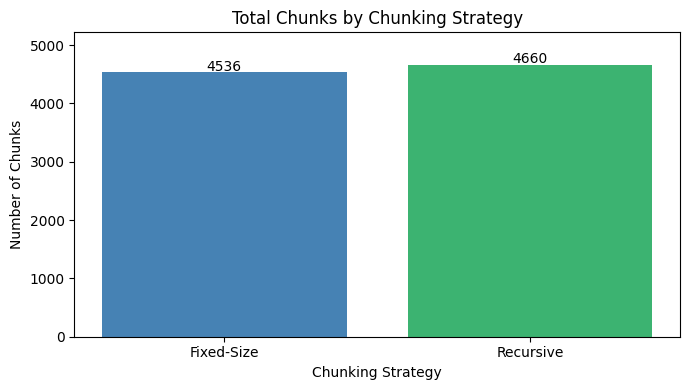

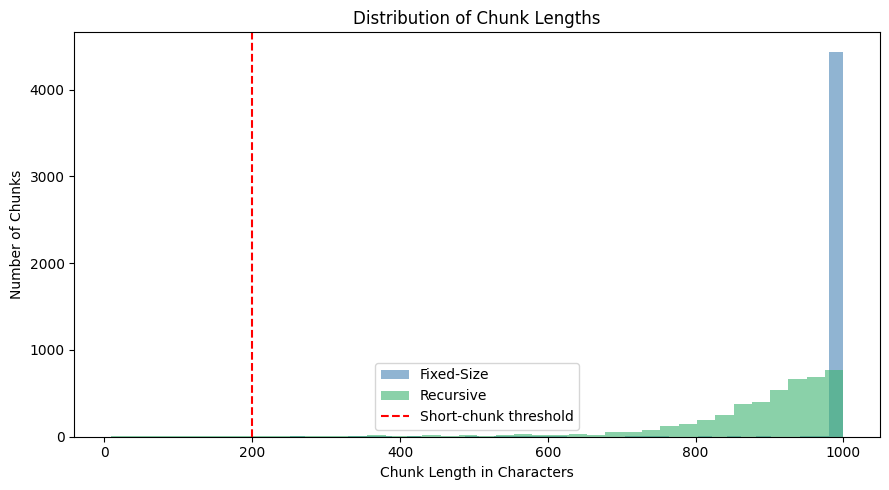


CHUNKING COMPARISON COMPLETED


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

SHORT_CHUNK_THRESHOLD = 200

chunking_comparison_df = pd.DataFrame({
    "Chunking Strategy": [
        "Fixed-Size",
        "Recursive"
    ],
    "Total Chunks": [
        len(fixed_chunks_df),
        len(recursive_chunks_df)
    ],
    "Mean Length": [
        fixed_chunks_df["character_count"].mean(),
        recursive_chunks_df["character_count"].mean()
    ],
    "Median Length": [
        fixed_chunks_df["character_count"].median(),
        recursive_chunks_df["character_count"].median()
    ],
    "Minimum Length": [
        fixed_chunks_df["character_count"].min(),
        recursive_chunks_df["character_count"].min()
    ],
    "Maximum Length": [
        fixed_chunks_df["character_count"].max(),
        recursive_chunks_df["character_count"].max()
    ],
    "Chunks Under 200 Characters": [
        (
            fixed_chunks_df["character_count"]
            < SHORT_CHUNK_THRESHOLD
        ).sum(),
        (
            recursive_chunks_df["character_count"]
            < SHORT_CHUNK_THRESHOLD
        ).sum()
    ]
})

print("=" * 75)
print("STRUCTURAL COMPARISON OF CHUNKING STRATEGIES")
print("=" * 75)

print(
    chunking_comparison_df
    .round(2)
    .to_string(index=False)
)

# Chart 1: total number of chunks
plt.figure(figsize=(7, 4))

bars = plt.bar(
    chunking_comparison_df["Chunking Strategy"],
    chunking_comparison_df["Total Chunks"],
    color=["steelblue", "mediumseagreen"]
)

plt.title("Total Chunks by Chunking Strategy")
plt.xlabel("Chunking Strategy")
plt.ylabel("Number of Chunks")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 25,
        f"{int(bar.get_height())}",
        ha="center"
    )

plt.ylim(
    0,
    chunking_comparison_df["Total Chunks"].max() * 1.12
)

plt.tight_layout()
plt.show()

# Chart 2: length distributions
plt.figure(figsize=(9, 5))

plt.hist(
    fixed_chunks_df["character_count"],
    bins=40,
    alpha=0.60,
    label="Fixed-Size",
    color="steelblue"
)

plt.hist(
    recursive_chunks_df["character_count"],
    bins=40,
    alpha=0.60,
    label="Recursive",
    color="mediumseagreen"
)

plt.axvline(
    SHORT_CHUNK_THRESHOLD,
    color="red",
    linestyle="--",
    label="Short-chunk threshold"
)

plt.title("Distribution of Chunk Lengths")
plt.xlabel("Chunk Length in Characters")
plt.ylabel("Number of Chunks")
plt.legend()
plt.tight_layout()
plt.show()

print("\n" + "=" * 75)
print("CHUNKING COMPARISON COMPLETED")
print("=" * 75)

## Task 2: Embedding and Vector Database Indexing

### 2.1 Load the Embedding Model

The `sentence-transformers/all-MiniLM-L6-v2` model will convert every document chunk into a dense semantic vector.

This model produces 384-dimensional embeddings. The embeddings will be normalized so that cosine similarity can be used consistently during retrieval.

In [10]:
from sentence_transformers import SentenceTransformer
import numpy as np
import torch

EMBEDDING_MODEL_NAME = (
    "sentence-transformers/all-MiniLM-L6-v2"
)

embedding_model = SentenceTransformer(
    EMBEDDING_MODEL_NAME,
    device=DEVICE
)

# Verify the model using two semantically related sentences
verification_sentences = [
    "Neural networks are used for image classification.",
    "Deep-learning models can identify objects in images."
]

verification_embeddings = embedding_model.encode(
    verification_sentences,
    normalize_embeddings=True,
    convert_to_numpy=True
)

verification_similarity = float(
    np.dot(
        verification_embeddings[0],
        verification_embeddings[1]
    )
)

embedding_dimension = (
    embedding_model.get_embedding_dimension()
)

print("=" * 65)
print("EMBEDDING MODEL VERIFICATION")
print("=" * 65)

print("Model:", EMBEDDING_MODEL_NAME)
print("Device:", embedding_model.device)
print("Embedding dimension:", embedding_dimension)
print(
    "Verification embedding shape:",
    verification_embeddings.shape
)
print(
    "Similarity between related sentences:",
    round(verification_similarity, 4)
)

assert verification_embeddings.shape == (
    2,
    embedding_dimension
)

assert np.isfinite(verification_embeddings).all()

print("\nEmbedding model loaded successfully.")
print("=" * 65)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

EMBEDDING MODEL VERIFICATION
Model: sentence-transformers/all-MiniLM-L6-v2
Device: cuda:0
Embedding dimension: 384
Verification embedding shape: (2, 384)
Similarity between related sentences: 0.5461

Embedding model loaded successfully.


### 2.2 Generate Embeddings for Both Chunking Strategies

Separate embeddings will be generated for:

- all fixed-size chunks;
- all recursive chunks.

The same model and normalization settings are used for both strategies to ensure a fair comparison.

In [11]:
from time import perf_counter
import numpy as np

EMBEDDING_BATCH_SIZE = 128

print("=" * 65)
print("GENERATING CHUNK EMBEDDINGS")
print("=" * 65)

# Fixed-size embeddings
print("\nGenerating fixed-size chunk embeddings...")

fixed_start_time = perf_counter()

fixed_embeddings = embedding_model.encode(
    fixed_chunks_df["chunk_text"].tolist(),
    batch_size=EMBEDDING_BATCH_SIZE,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)

fixed_embedding_time = (
    perf_counter() - fixed_start_time
)

# Recursive embeddings
print("\nGenerating recursive chunk embeddings...")

recursive_start_time = perf_counter()

recursive_embeddings = embedding_model.encode(
    recursive_chunks_df["chunk_text"].tolist(),
    batch_size=EMBEDDING_BATCH_SIZE,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)

recursive_embedding_time = (
    perf_counter() - recursive_start_time
)

# Validate the generated embeddings
assert fixed_embeddings.shape == (
    len(fixed_chunks_df),
    embedding_dimension
)

assert recursive_embeddings.shape == (
    len(recursive_chunks_df),
    embedding_dimension
)

assert np.isfinite(fixed_embeddings).all()
assert np.isfinite(recursive_embeddings).all()

print("\n" + "=" * 65)
print("EMBEDDING GENERATION SUMMARY")
print("=" * 65)

print("Embedding model:", EMBEDDING_MODEL_NAME)
print("Embedding dimension:", embedding_dimension)

print("\nFixed-size strategy")
print("Chunks:", len(fixed_chunks_df))
print("Embedding shape:", fixed_embeddings.shape)
print(
    "Processing time:",
    f"{fixed_embedding_time:.2f} seconds"
)

print("\nRecursive strategy")
print("Chunks:", len(recursive_chunks_df))
print("Embedding shape:", recursive_embeddings.shape)
print(
    "Processing time:",
    f"{recursive_embedding_time:.2f} seconds"
)

print(
    "\nTotal embeddings generated:",
    len(fixed_embeddings) + len(recursive_embeddings)
)

print("\nEMBEDDING GENERATION COMPLETED")

GENERATING CHUNK EMBEDDINGS

Generating fixed-size chunk embeddings...


Batches:   0%|          | 0/36 [00:00<?, ?it/s]


Generating recursive chunk embeddings...


Batches:   0%|          | 0/37 [00:00<?, ?it/s]


EMBEDDING GENERATION SUMMARY
Embedding model: sentence-transformers/all-MiniLM-L6-v2
Embedding dimension: 384

Fixed-size strategy
Chunks: 4536
Embedding shape: (4536, 384)
Processing time: 6.25 seconds

Recursive strategy
Chunks: 4660
Embedding shape: (4660, 384)
Processing time: 6.36 seconds

Total embeddings generated: 9196

EMBEDDING GENERATION COMPLETED


### 2.3 Store the Embeddings in ChromaDB

Two separate ChromaDB collections will be created:

- `arxiv_fixed_chunks` for fixed-size chunks;
- `arxiv_recursive_chunks` for recursive chunks.

Each database record contains:

- a unique chunk ID;
- the chunk text;
- its 384-dimensional embedding;
- its source document ID;
- its chunk index;
- its chunking strategy;
- its character count.

Cosine distance is used for similarity search.

In [12]:
import chromadb
from pathlib import Path

CHROMA_DATABASE_PATH = Path(
    "/content/homework10_chromadb"
)

chroma_client = chromadb.PersistentClient(
    path=str(CHROMA_DATABASE_PATH)
)

FIXED_COLLECTION_NAME = "arxiv_fixed_chunks"
RECURSIVE_COLLECTION_NAME = "arxiv_recursive_chunks"

# Remove only this notebook's old collections when rerunning
existing_collection_names = {
    collection.name
    for collection in chroma_client.list_collections()
}

if FIXED_COLLECTION_NAME in existing_collection_names:
    chroma_client.delete_collection(
        name=FIXED_COLLECTION_NAME
    )

if RECURSIVE_COLLECTION_NAME in existing_collection_names:
    chroma_client.delete_collection(
        name=RECURSIVE_COLLECTION_NAME
    )

# Create clean collections
fixed_collection = chroma_client.create_collection(
    name=FIXED_COLLECTION_NAME,
    metadata={"hnsw:space": "cosine"}
)

recursive_collection = chroma_client.create_collection(
    name=RECURSIVE_COLLECTION_NAME,
    metadata={"hnsw:space": "cosine"}
)


def store_chunks_in_chromadb(
    collection,
    chunks_df,
    embeddings,
    batch_size=200
):
    """
    Store chunk text, embeddings, IDs, and metadata
    in a ChromaDB collection.
    """
    if len(chunks_df) != len(embeddings):
        raise ValueError(
            "The number of chunks and embeddings must match."
        )

    total_records = len(chunks_df)

    for batch_start in range(
        0,
        total_records,
        batch_size
    ):
        batch_end = min(
            batch_start + batch_size,
            total_records
        )

        batch_df = chunks_df.iloc[
            batch_start:batch_end
        ]

        batch_embeddings = embeddings[
            batch_start:batch_end
        ]

        collection.upsert(
            ids=batch_df["chunk_id"].tolist(),
            documents=batch_df["chunk_text"].tolist(),
            embeddings=batch_embeddings.tolist(),
            metadatas=[
                {
                    "document_id": row["document_id"],
                    "chunk_index": int(row["chunk_index"]),
                    "strategy": row["strategy"],
                    "character_count": int(
                        row["character_count"]
                    )
                }
                for _, row in batch_df.iterrows()
            ]
        )

    return collection.count()


print("=" * 65)
print("CHROMADB VECTOR DATABASE INDEXING")
print("=" * 65)

print("Database path:", CHROMA_DATABASE_PATH)

print("\nStoring fixed-size chunks...")

fixed_record_count = store_chunks_in_chromadb(
    fixed_collection,
    fixed_chunks_df,
    fixed_embeddings
)

print("Fixed-size records stored:", fixed_record_count)

print("\nStoring recursive chunks...")

recursive_record_count = store_chunks_in_chromadb(
    recursive_collection,
    recursive_chunks_df,
    recursive_embeddings
)

print("Recursive records stored:", recursive_record_count)

# Validate database record counts
assert fixed_record_count == len(fixed_chunks_df)
assert recursive_record_count == len(
    recursive_chunks_df
)

print("\n" + "=" * 65)
print("CHROMADB INDEXING SUMMARY")
print("=" * 65)

print("Fixed-size collection:", fixed_collection.name)
print("Fixed-size records:", fixed_collection.count())

print(
    "Recursive collection:",
    recursive_collection.name
)
print(
    "Recursive records:",
    recursive_collection.count()
)

print(
    "Total indexed records:",
    fixed_collection.count()
    + recursive_collection.count()
)

print("\nCHROMADB INDEXING COMPLETED")

CHROMADB VECTOR DATABASE INDEXING
Database path: /content/homework10_chromadb

Storing fixed-size chunks...
Fixed-size records stored: 4536

Storing recursive chunks...
Recursive records stored: 4660

CHROMADB INDEXING SUMMARY
Fixed-size collection: arxiv_fixed_chunks
Fixed-size records: 4536
Recursive collection: arxiv_recursive_chunks
Recursive records: 4660
Total indexed records: 9196

CHROMADB INDEXING COMPLETED


## Task 3: Retrieval Without Reranking

### 3.1 Define the Sample Queries

Two research questions are used for the initial retrieval experiment:

1. What advantages do additive models have over fully nonparametric models?
2. How is quantile regression used with regularized kernel-based methods?

Both questions are submitted unchanged to both ChromaDB collections. The five chunks with the smallest cosine distance are returned from each collection.

No cross-encoder reranking is used in this stage.

In [13]:
SAMPLE_QUERIES = {
    "Q1": (
        "What are the advantages of additive models "
        "compared with fully nonparametric models?"
    ),
    "Q2": (
        "How is quantile regression used with "
        "regularized kernel-based methods?"
    )
}

BASELINE_TOP_K = 5

print("=" * 70)
print("SAMPLE RETRIEVAL QUERIES")
print("=" * 70)

for query_id, query_text in SAMPLE_QUERIES.items():
    print(f"\n{query_id}: {query_text}")

print("\nRetrieval depth:", BASELINE_TOP_K)
print("Similarity measure: cosine")
print("Reranking enabled: No")
print("Collections: Fixed-Size and Recursive")

SAMPLE RETRIEVAL QUERIES

Q1: What are the advantages of additive models compared with fully nonparametric models?

Q2: How is quantile regression used with regularized kernel-based methods?

Retrieval depth: 5
Similarity measure: cosine
Reranking enabled: No
Collections: Fixed-Size and Recursive


In [14]:
import pandas as pd


def retrieve_from_collection(
    query_id,
    query_text,
    collection,
    strategy,
    top_k=5
):
    """
    Retrieve the top-k chunks using embedding similarity only.
    """
    query_embedding = embedding_model.encode(
        [query_text],
        normalize_embeddings=True,
        convert_to_numpy=True
    )

    query_results = collection.query(
        query_embeddings=query_embedding.tolist(),
        n_results=top_k,
        include=[
            "documents",
            "metadatas",
            "distances"
        ]
    )

    retrieved_records = []

    for result_index, chunk_id in enumerate(
        query_results["ids"][0]
    ):
        metadata = (
            query_results["metadatas"][0][result_index]
        )

        distance = float(
            query_results["distances"][0][result_index]
        )

        chunk_text = (
            query_results["documents"][0][result_index]
        )

        retrieved_records.append({
            "query_id": query_id,
            "query": query_text,
            "strategy": strategy,
            "rank": result_index + 1,
            "chunk_id": chunk_id,
            "document_id": metadata["document_id"],
            "cosine_distance": distance,
            "cosine_similarity": 1 - distance,
            "chunk_text": chunk_text
        })

    return retrieved_records


collections_by_strategy = {
    "Fixed-Size": fixed_collection,
    "Recursive": recursive_collection
}

baseline_records = []

for strategy, collection in (
    collections_by_strategy.items()
):
    for query_id, query_text in (
        SAMPLE_QUERIES.items()
    ):
        query_records = retrieve_from_collection(
            query_id=query_id,
            query_text=query_text,
            collection=collection,
            strategy=strategy,
            top_k=BASELINE_TOP_K
        )

        baseline_records.extend(query_records)


baseline_results_df = pd.DataFrame(
    baseline_records
)

expected_baseline_records = (
    len(SAMPLE_QUERIES)
    * len(collections_by_strategy)
    * BASELINE_TOP_K
)

assert len(baseline_results_df) == (
    expected_baseline_records
)

assert baseline_results_df["chunk_id"].notna().all()

assert baseline_results_df[
    "cosine_similarity"
].notna().all()

print("=" * 80)
print("BASELINE RETRIEVAL RESULTS — NO RERANKING")
print("=" * 80)

for (strategy, query_id), group in (
    baseline_results_df.groupby(
        ["strategy", "query_id"],
        sort=False
    )
):
    group = group.sort_values("rank").copy()

    group["passage_preview"] = (
        group["chunk_text"]
        .str.slice(0, 180)
        .str.replace("\n", " ", regex=False)
        + "..."
    )

    print(f"\nStrategy: {strategy}")
    print(f"Query ID: {query_id}")
    print("Question:", group["query"].iloc[0])
    print("-" * 80)

    display(
        group[
            [
                "rank",
                "chunk_id",
                "document_id",
                "cosine_similarity",
                "passage_preview"
            ]
        ].round({
            "cosine_similarity": 4
        }).reset_index(drop=True)
    )

print("\n" + "=" * 80)
print("BASELINE RETRIEVAL SUMMARY")
print("=" * 80)

print("Number of queries:", len(SAMPLE_QUERIES))
print(
    "Number of chunking strategies:",
    len(collections_by_strategy)
)
print("Results per query and strategy:", BASELINE_TOP_K)
print(
    "Total retrieved records:",
    len(baseline_results_df)
)
print("Reranking applied: No")

BASELINE RETRIEVAL RESULTS — NO RERANKING

Strategy: Fixed-Size
Query ID: Q1
Question: What are the advantages of additive models compared with fully nonparametric models?
--------------------------------------------------------------------------------


,rank,chunk_id,document_id,cosine_similarity,passage_preview
0,1,doc_000_fixed_0000,doc_000,0.5702,additive models @xcite provide an important fa...
1,2,doc_000_fixed_0023,doc_000,0.4849,"already mentioned in the introduction , some r..."
2,3,doc_000_fixed_0003,doc_000,0.4294,itive model is satisfied . our leading example...
3,4,doc_000_fixed_0016,doc_000,0.3726,h148 of the components in the additive model ....
4,5,doc_000_fixed_0010,doc_000,0.3452,special cases . section [ comparisonsection ]...



Strategy: Fixed-Size
Query ID: Q2
Question: How is quantile regression used with regularized kernel-based methods?
--------------------------------------------------------------------------------


,rank,chunk_id,document_id,cosine_similarity,passage_preview
0,1,doc_000_fixed_0001,doc_000,0.6947,when the focus is on sparsity and when the cla...
1,2,doc_000_fixed_0002,doc_000,0.6145,", we will here consider the case of regularize..."
2,3,doc_000_fixed_0003,doc_000,0.5945,itive model is satisfied . our leading example...
3,4,doc_000_fixed_0017,doc_000,0.5787,he hypothesis space . before stating the gener...
4,5,doc_000_fixed_0000,doc_000,0.5776,additive models @xcite provide an important fa...



Strategy: Recursive
Query ID: Q1
Question: What are the advantages of additive models compared with fully nonparametric models?
--------------------------------------------------------------------------------


,rank,chunk_id,document_id,cosine_similarity,passage_preview
0,1,doc_000_recursive_0000,doc_000,0.5623,additive models @xcite provide an important fa...
1,2,doc_000_recursive_0023,doc_000,0.4679,. [ mainratesthm ] suppose that @xmath228 is b...
2,3,doc_000_recursive_0003,doc_000,0.4366,. we will not address the question how to chec...
3,4,doc_000_recursive_0007,doc_000,0.3939,. the additive kernel @xmath40 is defined in t...
4,5,doc_000_recursive_0010,doc_000,0.3576,. the rest of the paper has the following stru...



Strategy: Recursive
Query ID: Q2
Question: How is quantile regression used with regularized kernel-based methods?
--------------------------------------------------------------------------------


,rank,chunk_id,document_id,cosine_similarity,passage_preview
0,1,doc_000_recursive_0002,doc_000,0.6841,. such regularized kernel based methods are no...
1,2,doc_000_recursive_0020,doc_000,0.6798,". the following theorem , to be proved in sect..."
2,3,doc_000_recursive_0001,doc_000,0.6564,". of course , the least squares loss function ..."
3,4,doc_000_recursive_0024,doc_000,0.6476,". in other words , we need to demonstrate that..."
4,5,doc_000_recursive_0017,doc_000,0.5898,. the special bound in theorem [ capacitythm ]...



BASELINE RETRIEVAL SUMMARY
Number of queries: 2
Number of chunking strategies: 2
Results per query and strategy: 5
Total retrieved records: 20
Reranking applied: No


## Task 4: Retrieval With Cross-Encoder Reranking

### 4.1 Load the Reranking Model

Vector similarity provides efficient initial retrieval, but it scores queries and passages independently.

The `cross-encoder/ms-marco-MiniLM-L-6-v2` model evaluates each query-passage pair jointly. This usually produces a more precise relevance score.

For each query and chunking strategy:

1. ChromaDB retrieves the top 20 candidates.
2. The cross-encoder scores all 20 candidates.
3. The candidates are sorted by cross-encoder score.
4. The best five passages are retained.

In [15]:
from sentence_transformers import CrossEncoder
import numpy as np

RERANKER_MODEL_NAME = (
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)

CANDIDATE_TOP_K = 20
RERANKED_TOP_K = 5

reranker = CrossEncoder(
    RERANKER_MODEL_NAME,
    device=DEVICE
)

# Verify the reranker with one relevant and one unrelated passage
verification_question = (
    "What are the advantages of additive models?"
)

verification_passages = [
    (
        "Additive models are interpretable and are less "
        "affected by the curse of dimensionality."
    ),
    (
        "This passage describes telescope hardware and "
        "astronomical image sensors."
    )
]

verification_pairs = [
    (verification_question, passage)
    for passage in verification_passages
]

verification_scores = np.asarray(
    reranker.predict(
        verification_pairs,
        show_progress_bar=False
    )
).reshape(-1)

print("=" * 65)
print("CROSS-ENCODER RERANKER VERIFICATION")
print("=" * 65)

print("Model:", RERANKER_MODEL_NAME)
print("Device:", reranker.device)
print("Candidate retrieval depth:", CANDIDATE_TOP_K)
print("Final retrieval depth:", RERANKED_TOP_K)

for index, score in enumerate(
    verification_scores,
    start=1
):
    print(
        f"Passage {index} score: "
        f"{float(score):.4f}"
    )

assert len(verification_scores) == 2
assert np.isfinite(verification_scores).all()
assert verification_scores[0] > verification_scores[1]

print("\nReranker verification passed.")

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

CROSS-ENCODER RERANKER VERIFICATION
Model: cross-encoder/ms-marco-MiniLM-L-6-v2
Device: cuda:0
Candidate retrieval depth: 20
Final retrieval depth: 5
Passage 1 score: 3.4139
Passage 2 score: -11.3690

Reranker verification passed.


### 4.2 Rerank the Same Sample Queries

The same Q1 and Q2 questions used in baseline retrieval are now used for reranking.

The reranker does not search the entire database. Instead, it reorders the top 20 candidates returned by ChromaDB and selects the five highest-scoring passages.

In [16]:
import pandas as pd
import numpy as np

all_candidate_groups = []
reranked_top5_groups = []

for strategy, collection in (
    collections_by_strategy.items()
):
    for query_id, query_text in (
        SAMPLE_QUERIES.items()
    ):
        # Retrieve the top 20 candidates
        candidate_records = retrieve_from_collection(
            query_id=query_id,
            query_text=query_text,
            collection=collection,
            strategy=strategy,
            top_k=CANDIDATE_TOP_K
        )

        candidate_df = pd.DataFrame(
            candidate_records
        ).rename(
            columns={"rank": "original_rank"}
        )

        # Build query-passage pairs
        query_passage_pairs = [
            (query_text, passage)
            for passage in candidate_df[
                "chunk_text"
            ].tolist()
        ]

        # Score every pair with the cross-encoder
        reranker_scores = reranker.predict(
            query_passage_pairs,
            batch_size=16,
            show_progress_bar=False
        )

        candidate_df["reranker_score"] = (
            np.asarray(reranker_scores).reshape(-1)
        )

        # Reorder by cross-encoder score
        candidate_df = (
            candidate_df.sort_values(
                [
                    "reranker_score",
                    "original_rank"
                ],
                ascending=[False, True]
            )
            .reset_index(drop=True)
        )

        candidate_df["reranked_rank"] = (
            np.arange(1, len(candidate_df) + 1)
        )

        all_candidate_groups.append(candidate_df)

        reranked_top5_groups.append(
            candidate_df.head(
                RERANKED_TOP_K
            ).copy()
        )


reranked_candidates_df = pd.concat(
    all_candidate_groups,
    ignore_index=True
)

reranked_results_df = pd.concat(
    reranked_top5_groups,
    ignore_index=True
)

expected_candidate_count = (
    len(SAMPLE_QUERIES)
    * len(collections_by_strategy)
    * CANDIDATE_TOP_K
)

expected_reranked_count = (
    len(SAMPLE_QUERIES)
    * len(collections_by_strategy)
    * RERANKED_TOP_K
)

assert len(reranked_candidates_df) == (
    expected_candidate_count
)

assert len(reranked_results_df) == (
    expected_reranked_count
)

assert np.isfinite(
    reranked_candidates_df["reranker_score"]
).all()

print("=" * 80)
print("RERANKED RETRIEVAL RESULTS")
print("=" * 80)

for (strategy, query_id), group in (
    reranked_results_df.groupby(
        ["strategy", "query_id"],
        sort=False
    )
):
    group = group.sort_values(
        "reranked_rank"
    ).copy()

    group["passage_preview"] = (
        group["chunk_text"]
        .str.slice(0, 180)
        .str.replace("\n", " ", regex=False)
        + "..."
    )

    print(f"\nStrategy: {strategy}")
    print(f"Query ID: {query_id}")
    print("Question:", group["query"].iloc[0])
    print("-" * 80)

    display(
        group[
            [
                "reranked_rank",
                "original_rank",
                "chunk_id",
                "document_id",
                "cosine_similarity",
                "reranker_score",
                "passage_preview"
            ]
        ].round({
            "cosine_similarity": 4,
            "reranker_score": 4
        }).reset_index(drop=True)
    )

print("\n" + "=" * 80)
print("RERANKING SUMMARY")
print("=" * 80)

print("Queries:", len(SAMPLE_QUERIES))
print(
    "Chunking strategies:",
    len(collections_by_strategy)
)
print("Candidates per query:", CANDIDATE_TOP_K)
print("Final passages per query:", RERANKED_TOP_K)
print(
    "Total candidates reranked:",
    len(reranked_candidates_df)
)
print(
    "Total final reranked passages:",
    len(reranked_results_df)
)

RERANKED RETRIEVAL RESULTS

Strategy: Fixed-Size
Query ID: Q1
Question: What are the advantages of additive models compared with fully nonparametric models?
--------------------------------------------------------------------------------


,reranked_rank,original_rank,chunk_id,document_id,cosine_similarity,reranker_score,passage_preview
0,1,1,doc_000_fixed_0000,doc_000,0.5702,6.9933,additive models @xcite provide an important fa...
1,2,2,doc_000_fixed_0023,doc_000,0.4849,1.4467,"already mentioned in the introduction , some r..."
2,3,3,doc_000_fixed_0003,doc_000,0.4294,-0.9423,itive model is satisfied . our leading example...
3,4,4,doc_000_fixed_0016,doc_000,0.3726,-1.5191,h148 of the components in the additive model ....
4,5,7,doc_000_fixed_0007,doc_000,0.3200,-2.4761,ecifying these quantities with different symbo...



Strategy: Fixed-Size
Query ID: Q2
Question: How is quantile regression used with regularized kernel-based methods?
--------------------------------------------------------------------------------


,reranked_rank,original_rank,chunk_id,document_id,cosine_similarity,reranker_score,passage_preview
0,1,2,doc_000_fixed_0002,doc_000,0.6145,6.1847,", we will here consider the case of regularize..."
1,2,1,doc_000_fixed_0001,doc_000,0.6947,2.8057,when the focus is on sparsity and when the cla...
2,3,3,doc_000_fixed_0003,doc_000,0.5945,1.6429,itive model is satisfied . our leading example...
3,4,5,doc_000_fixed_0000,doc_000,0.5776,1.5994,additive models @xcite provide an important fa...
4,5,12,doc_000_fixed_0020,doc_000,0.4950,0.8911,the special case of quantile regression . [ q...



Strategy: Recursive
Query ID: Q1
Question: What are the advantages of additive models compared with fully nonparametric models?
--------------------------------------------------------------------------------


,reranked_rank,original_rank,chunk_id,document_id,cosine_similarity,reranker_score,passage_preview
0,1,1,doc_000_recursive_0000,doc_000,0.5623,7.0397,additive models @xcite provide an important fa...
1,2,4,doc_000_recursive_0007,doc_000,0.3939,-0.7704,. the additive kernel @xmath40 is defined in t...
2,3,9,doc_000_recursive_0017,doc_000,0.2975,-1.0182,. the special bound in theorem [ capacitythm ]...
3,4,3,doc_000_recursive_0003,doc_000,0.4366,-1.8304,. we will not address the question how to chec...
4,5,8,doc_000_recursive_0002,doc_000,0.2989,-2.3613,. such regularized kernel based methods are no...



Strategy: Recursive
Query ID: Q2
Question: How is quantile regression used with regularized kernel-based methods?
--------------------------------------------------------------------------------


,reranked_rank,original_rank,chunk_id,document_id,cosine_similarity,reranker_score,passage_preview
0,1,1,doc_000_recursive_0002,doc_000,0.6841,6.8401,. such regularized kernel based methods are no...
1,2,2,doc_000_recursive_0020,doc_000,0.6798,4.5429,". the following theorem , to be proved in sect..."
2,3,3,doc_000_recursive_0001,doc_000,0.6564,2.2727,". of course , the least squares loss function ..."
3,4,7,doc_000_recursive_0000,doc_000,0.5771,1.5396,additive models @xcite provide an important fa...
4,5,8,doc_000_recursive_0026,doc_000,0.5662,1.5147,". for a @xmath193 kernel and @xmath112 , one c..."



RERANKING SUMMARY
Queries: 2
Chunking strategies: 2
Candidates per query: 20
Final passages per query: 5
Total candidates reranked: 80
Total final reranked passages: 20


### 4.3 Compare Rankings Before and After Reranking

The baseline and reranked top-five results are compared using:

- number of chunks shared by both top-five lists;
- number of new chunks promoted into the reranked top five;
- percentage overlap;
- original and reranked positions of promoted passages.

This describes how much the ranking changed. Precision@K, Recall@K, and MRR will later determine whether the changes improved relevance.

In [17]:
import pandas as pd

ranking_comparison_records = []
promoted_passage_records = []

for strategy in collections_by_strategy:

    for query_id, query_text in (
        SAMPLE_QUERIES.items()
    ):
        baseline_group = baseline_results_df[
            (
                baseline_results_df["strategy"]
                == strategy
            )
            & (
                baseline_results_df["query_id"]
                == query_id
            )
        ].sort_values("rank")

        reranked_group = reranked_results_df[
            (
                reranked_results_df["strategy"]
                == strategy
            )
            & (
                reranked_results_df["query_id"]
                == query_id
            )
        ].sort_values("reranked_rank")

        baseline_chunk_ids = set(
            baseline_group["chunk_id"]
        )

        reranked_chunk_ids = set(
            reranked_group["chunk_id"]
        )

        shared_chunk_ids = (
            baseline_chunk_ids
            & reranked_chunk_ids
        )

        promoted_chunk_ids = (
            reranked_chunk_ids
            - baseline_chunk_ids
        )

        ranking_comparison_records.append({
            "Strategy": strategy,
            "Query": query_id,
            "Shared Top-5 Chunks": len(
                shared_chunk_ids
            ),
            "Newly Promoted Chunks": len(
                promoted_chunk_ids
            ),
            "Top-5 Overlap (%)": (
                len(shared_chunk_ids)
                / BASELINE_TOP_K
                * 100
            )
        })

        for _, result_row in (
            reranked_group.iterrows()
        ):
            if (
                result_row["chunk_id"]
                in promoted_chunk_ids
            ):
                promoted_passage_records.append({
                    "Strategy": strategy,
                    "Query": query_id,
                    "Chunk ID": result_row[
                        "chunk_id"
                    ],
                    "Document ID": result_row[
                        "document_id"
                    ],
                    "Original Rank": int(
                        result_row["original_rank"]
                    ),
                    "Reranked Rank": int(
                        result_row["reranked_rank"]
                    ),
                    "Reranker Score": float(
                        result_row["reranker_score"]
                    ),
                    "Passage Preview": (
                        result_row["chunk_text"][:220]
                        + "..."
                    )
                })


ranking_comparison_df = pd.DataFrame(
    ranking_comparison_records
)

promoted_passages_df = pd.DataFrame(
    promoted_passage_records
)

print("=" * 80)
print("BASELINE VERSUS RERANKED TOP-5 COMPARISON")
print("=" * 80)

display(
    ranking_comparison_df.round(2)
)

print("\nNEWLY PROMOTED PASSAGES")
print("-" * 80)

if promoted_passages_df.empty:
    print(
        "No passages were promoted from outside "
        "the baseline top five."
    )
else:
    display(
        promoted_passages_df[
            [
                "Strategy",
                "Query",
                "Chunk ID",
                "Document ID",
                "Original Rank",
                "Reranked Rank",
                "Reranker Score",
                "Passage Preview"
            ]
        ].round({
            "Reranker Score": 4
        }).reset_index(drop=True)
    )

print("\nRANKING COMPARISON COMPLETED")

BASELINE VERSUS RERANKED TOP-5 COMPARISON


,Strategy,Query,Shared Top-5 Chunks,Newly Promoted Chunks,Top-5 Overlap (%)
0,Fixed-Size,Q1,4,1,80.0
1,Fixed-Size,Q2,4,1,80.0
2,Recursive,Q1,3,2,60.0
3,Recursive,Q2,3,2,60.0



NEWLY PROMOTED PASSAGES
--------------------------------------------------------------------------------


,Strategy,Query,Chunk ID,Document ID,Original Rank,Reranked Rank,Reranker Score,Passage Preview
0,Fixed-Size,Q1,doc_000_fixed_0007,doc_000,7,5,-2.4761,ecifying these quantities with different symbo...
1,Fixed-Size,Q2,doc_000_fixed_0020,doc_000,12,5,0.8911,the special case of quantile regression . [ q...
2,Recursive,Q1,doc_000_recursive_0017,doc_000,9,3,-1.0182,. the special bound in theorem [ capacitythm ]...
3,Recursive,Q1,doc_000_recursive_0002,doc_000,8,5,-2.3613,. such regularized kernel based methods are no...
4,Recursive,Q2,doc_000_recursive_0000,doc_000,7,4,1.5396,additive models @xcite provide an important fa...
5,Recursive,Q2,doc_000_recursive_0026,doc_000,8,5,1.5147,". for a @xmath193 kernel and @xmath112 , one c..."



RANKING COMPARISON COMPLETED


## Task 5: Conversational Memory

### 5.1 Multi-Turn Query

A two-turn conversation is used to test conversational retrieval:

- Turn 1: “What are the advantages of additive models?”
- Turn 2: “How do they help in high-dimensional problems?”

The phrase “they” in the second question depends on the topic introduced during the first turn.

Without memory, the retriever receives the ambiguous question unchanged.

With memory, the mechanism identifies the previous topic and rewrites the follow-up as:

“How do additive models help in high-dimensional problems?”

In [18]:
import re


class SimpleConversationMemory:
    """
    Store conversation history and resolve simple
    follow-up references using the most recent topic.
    """

    def __init__(self):
        self.history = []
        self.current_topic = None

    def add_message(self, role, message):
        self.history.append({
            "role": role,
            "message": message
        })

        if role == "user":
            extracted_topic = self.extract_topic(
                message
            )

            if extracted_topic:
                self.current_topic = (
                    extracted_topic
                )

    def extract_topic(self, message):
        """
        Extract the subject following phrases such as
        'advantages of' or 'benefits of'.
        """
        topic_pattern = re.compile(
            r"\b(?:advantages|benefits|limitations|"
            r"disadvantages)\s+of\s+"
            r"(.+?)(?:\?|$)",
            flags=re.IGNORECASE
        )

        topic_match = topic_pattern.search(message)

        if topic_match:
            return topic_match.group(1).strip()

        return None

    def rewrite_query(self, query):
        """
        Replace supported pronouns with the most
        recently remembered topic.
        """
        if self.current_topic is None:
            return query

        rewritten_query = re.sub(
            r"\bthey\b",
            self.current_topic,
            query,
            flags=re.IGNORECASE
        )

        rewritten_query = re.sub(
            r"\bthese models\b",
            self.current_topic,
            rewritten_query,
            flags=re.IGNORECASE
        )

        return rewritten_query

    def display_history(self):
        for turn_number, item in enumerate(
            self.history,
            start=1
        ):
            print(
                f"{turn_number}. "
                f"{item['role']}: "
                f"{item['message']}"
            )


conversation_memory = SimpleConversationMemory()

first_turn_query = (
    "What are the advantages of additive models?"
)

follow_up_query = (
    "How do they help in high-dimensional problems?"
)

# Store the first turn
conversation_memory.add_message(
    "user",
    first_turn_query
)

# Rewrite the dependent second turn
rewritten_follow_up_query = (
    conversation_memory.rewrite_query(
        follow_up_query
    )
)

# Store the original follow-up in history
conversation_memory.add_message(
    "user",
    follow_up_query
)

print("=" * 75)
print("CONVERSATIONAL MEMORY VERIFICATION")
print("=" * 75)

print("\nConversation history:")
conversation_memory.display_history()

print(
    "\nRemembered topic:",
    conversation_memory.current_topic
)

print("\nOriginal follow-up query:")
print(follow_up_query)

print("\nRewritten follow-up query:")
print(rewritten_follow_up_query)

assert (
    conversation_memory.current_topic
    == "additive models"
)

assert rewritten_follow_up_query == (
    "How do additive models help "
    "in high-dimensional problems?"
)

assert len(conversation_memory.history) == 2

print("\nConversational memory verification passed.")

CONVERSATIONAL MEMORY VERIFICATION

Conversation history:
1. user: What are the advantages of additive models?
2. user: How do they help in high-dimensional problems?

Remembered topic: additive models

Original follow-up query:
How do they help in high-dimensional problems?

Rewritten follow-up query:
How do additive models help in high-dimensional problems?

Conversational memory verification passed.


### 5.2 Compare Retrieval Without and With Memory

The follow-up question is retrieved under two conditions:

- Without memory: the ambiguous question is used unchanged.
- With memory: the pronoun is replaced with the remembered topic.

Both conditions are tested against both chunking strategies using the same embedding model and top-five retrieval depth.

In [19]:
import pandas as pd

MEMORY_TOP_K = 5

memory_query_conditions = {
    "Without Memory": follow_up_query,
    "With Memory": rewritten_follow_up_query
}

memory_retrieval_records = []

for strategy, collection in (
    collections_by_strategy.items()
):
    for condition, query_text in (
        memory_query_conditions.items()
    ):
        condition_records = retrieve_from_collection(
            query_id="FollowUp_Q2",
            query_text=query_text,
            collection=collection,
            strategy=strategy,
            top_k=MEMORY_TOP_K
        )

        for record in condition_records:
            record["memory_condition"] = condition

        memory_retrieval_records.extend(
            condition_records
        )


memory_results_df = pd.DataFrame(
    memory_retrieval_records
)

expected_memory_records = (
    len(collections_by_strategy)
    * len(memory_query_conditions)
    * MEMORY_TOP_K
)

assert len(memory_results_df) == (
    expected_memory_records
)

assert memory_results_df[
    "chunk_id"
].notna().all()

print("=" * 80)
print("RETRIEVAL WITHOUT AND WITH MEMORY")
print("=" * 80)

for strategy in collections_by_strategy:

    print(f"\nCHUNKING STRATEGY: {strategy}")
    print("=" * 80)

    for condition in [
        "Without Memory",
        "With Memory"
    ]:
        condition_group = memory_results_df[
            (
                memory_results_df["strategy"]
                == strategy
            )
            & (
                memory_results_df[
                    "memory_condition"
                ]
                == condition
            )
        ].sort_values("rank").copy()

        condition_group["passage_preview"] = (
            condition_group["chunk_text"]
            .str.slice(0, 180)
            .str.replace("\n", " ", regex=False)
            + "..."
        )

        print(f"\nCondition: {condition}")
        print(
            "Query:",
            condition_group["query"].iloc[0]
        )
        print("-" * 80)

        display(
            condition_group[
                [
                    "rank",
                    "chunk_id",
                    "document_id",
                    "cosine_similarity",
                    "passage_preview"
                ]
            ].round({
                "cosine_similarity": 4
            }).reset_index(drop=True)
        )

print("\n" + "=" * 80)
print("MEMORY RETRIEVAL SUMMARY")
print("=" * 80)

print("Conversation turns:", 2)
print("Memory conditions:", 2)
print("Chunking strategies:", 2)
print("Results per condition:", MEMORY_TOP_K)
print(
    "Total retrieved records:",
    len(memory_results_df)
)

RETRIEVAL WITHOUT AND WITH MEMORY

CHUNKING STRATEGY: Fixed-Size

Condition: Without Memory
Query: How do they help in high-dimensional problems?
--------------------------------------------------------------------------------


,rank,chunk_id,document_id,cosine_similarity,passage_preview
0,1,doc_084_fixed_0004,doc_084,0.3899,d series of computer experiments with linear i...
1,2,doc_000_fixed_0031,doc_000,0.3710,ive with the exceptions if @xmath286 or @xmath...
2,3,doc_093_fixed_0010,doc_093,0.3570,t of 2-d points around the origin and _ scale ...
3,4,doc_000_fixed_0023,doc_000,0.3486,"already mentioned in the introduction , some r..."
4,5,doc_083_fixed_0022,doc_083,0.3443,") , also holds when we calculate the self - d..."



Condition: With Memory
Query: How do additive models help in high-dimensional problems?
--------------------------------------------------------------------------------


,rank,chunk_id,document_id,cosine_similarity,passage_preview
0,1,doc_000_fixed_0023,doc_000,0.5447,"already mentioned in the introduction , some r..."
1,2,doc_000_fixed_0000,doc_000,0.5072,additive models @xcite provide an important fa...
2,3,doc_000_fixed_0016,doc_000,0.4393,h148 of the components in the additive model ....
3,4,doc_000_fixed_0010,doc_000,0.4109,special cases . section [ comparisonsection ]...
4,5,doc_000_fixed_0031,doc_000,0.4037,ive with the exceptions if @xmath286 or @xmath...



CHUNKING STRATEGY: Recursive

Condition: Without Memory
Query: How do they help in high-dimensional problems?
--------------------------------------------------------------------------------


,rank,chunk_id,document_id,cosine_similarity,passage_preview
0,1,doc_000_recursive_0032,doc_000,0.4183,". 4.12 ) , because @xmath288 table [ table2 ] ..."
1,2,doc_093_recursive_0010,doc_093,0.3965,. this is a commonly used representation in co...
2,3,doc_089_recursive_0050,doc_089,0.3803,". , hurley j.r . , 2002 , apj , 571 , 830 spur..."
3,4,doc_039_recursive_0001,doc_039,0.3406,". while for the multifractal process , e.g. , ..."
4,5,doc_083_recursive_0005,doc_083,0.3187,". when taking this multiscale approach , it is..."



Condition: With Memory
Query: How do additive models help in high-dimensional problems?
--------------------------------------------------------------------------------


,rank,chunk_id,document_id,cosine_similarity,passage_preview
0,1,doc_000_recursive_0023,doc_000,0.4982,. [ mainratesthm ] suppose that @xmath228 is b...
1,2,doc_000_recursive_0000,doc_000,0.4910,additive models @xcite provide an important fa...
2,3,doc_000_recursive_0003,doc_000,0.4718,. we will not address the question how to chec...
3,4,doc_000_recursive_0007,doc_000,0.4138,. the additive kernel @xmath40 is defined in t...
4,5,doc_000_recursive_0032,doc_000,0.3959,". 4.12 ) , because @xmath288 table [ table2 ] ..."



MEMORY RETRIEVAL SUMMARY
Conversation turns: 2
Memory conditions: 2
Chunking strategies: 2
Results per condition: 5
Total retrieved records: 20


## Task 6: Retrieval Evaluation

### 6.1 Human Relevance Judgments

Retrieval will be evaluated using human relevance judgments.

For every combination of:

- two sample queries;
- two chunking strategies;
- 20 candidate passages;

each passage will be assigned one binary label:

- `1` — the passage is useful for answering the query;
- `0` — the passage is not useful for answering the query.

The same relevance label will be used when evaluating the baseline and reranked positions. This ensures that the two ranking methods are compared fairly.

The candidate pool contains:

2 queries × 2 chunking strategies × 20 passages = 80 judgments.

In [20]:
from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount("/content/drive")

EVALUATION_DIRECTORY = Path(
    "/content/drive/MyDrive/"
    "DATA266_HW10_CLEAN/evaluation"
)

EVALUATION_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True
)

RETRIEVAL_JUDGMENT_FILE = (
    EVALUATION_DIRECTORY
    / "retrieval_relevance_judgments.csv"
)

# Create one record for every unique candidate passage
new_retrieval_judgments_df = (
    reranked_candidates_df[
        [
            "query_id",
            "query",
            "strategy",
            "chunk_id",
            "document_id",
            "original_rank",
            "reranked_rank",
            "cosine_similarity",
            "reranker_score",
            "chunk_text"
        ]
    ]
    .drop_duplicates(
        subset=[
            "query_id",
            "strategy",
            "chunk_id"
        ]
    )
    .sort_values(
        [
            "query_id",
            "strategy",
            "original_rank"
        ]
    )
    .reset_index(drop=True)
)

if RETRIEVAL_JUDGMENT_FILE.exists():
    print(
        "Existing judgment file found. "
        "Preserving all previous labels."
    )

    retrieval_judgments_df = pd.read_csv(
        RETRIEVAL_JUDGMENT_FILE
    )

else:
    print(
        "No existing judgment file found. "
        "Creating a new worksheet."
    )

    retrieval_judgments_df = (
        new_retrieval_judgments_df.copy()
    )

    retrieval_judgments_df["relevance"] = pd.NA
    retrieval_judgments_df["review_notes"] = ""

    retrieval_judgments_df.to_csv(
        RETRIEVAL_JUDGMENT_FILE,
        index=False
    )

retrieval_judgments_df["relevance"] = (
    pd.to_numeric(
        retrieval_judgments_df["relevance"],
        errors="coerce"
    )
)

assert len(retrieval_judgments_df) == 80
assert retrieval_judgments_df[
    ["query_id", "strategy", "chunk_id"]
].duplicated().sum() == 0

print("=" * 75)
print("RETRIEVAL RELEVANCE WORKSHEET")
print("=" * 75)

print(
    "Total passages:",
    len(retrieval_judgments_df)
)

print(
    "Reviewed:",
    retrieval_judgments_df[
        "relevance"
    ].notna().sum()
)

print(
    "Remaining:",
    retrieval_judgments_df[
        "relevance"
    ].isna().sum()
)

print("\nSaved to:")
print(RETRIEVAL_JUDGMENT_FILE)

Mounted at /content/drive
No existing judgment file found. Creating a new worksheet.
RETRIEVAL RELEVANCE WORKSHEET
Total passages: 80
Reviewed: 0
Remaining: 80

Saved to:
/content/drive/MyDrive/DATA266_HW10_CLEAN/evaluation/retrieval_relevance_judgments.csv


### Relevance-Labeling Criteria

A passage should be labeled relevant (`1`) when it contains information that would help answer the displayed question.

A passage should be labeled not relevant (`0`) when it:

- discusses an unrelated topic;
- contains only formulas or details that do not help answer the question;
- merely mentions a keyword without supplying useful information;
- is too incomplete to contribute to an answer.

Judgments should be based on usefulness, not solely on whether the passage comes from the expected source document.

In [21]:
import pandas as pd
import ipywidgets as widgets

from IPython.display import display, clear_output


def load_retrieval_judgments():
    review_data = pd.read_csv(
        RETRIEVAL_JUDGMENT_FILE
    )

    review_data["relevance"] = pd.to_numeric(
        review_data["relevance"],
        errors="coerce"
    )

    return review_data


review_df = load_retrieval_judgments()

current_review_index = [None]

progress_display = widgets.HTML()
passage_display = widgets.Output()

relevant_button = widgets.Button(
    description="Relevant (1)",
    button_style="success"
)

irrelevant_button = widgets.Button(
    description="Not Relevant (0)",
    button_style="danger"
)

previous_button = widgets.Button(
    description="Previous",
    button_style=""
)

skip_button = widgets.Button(
    description="Skip",
    button_style="warning"
)


def save_review_file():
    review_df.to_csv(
        RETRIEVAL_JUDGMENT_FILE,
        index=False
    )


def find_next_unreviewed(start_index=0):
    total_rows = len(review_df)

    for index in range(
        start_index,
        total_rows
    ):
        if pd.isna(
            review_df.loc[index, "relevance"]
        ):
            return index

    for index in range(0, start_index):
        if pd.isna(
            review_df.loc[index, "relevance"]
        ):
            return index

    return None


def display_current_passage():
    reviewed_count = review_df[
        "relevance"
    ].notna().sum()

    total_count = len(review_df)

    progress_display.value = (
        f"<b>Reviewed:</b> "
        f"{reviewed_count}/{total_count} "
        f"&nbsp;&nbsp; "
        f"<b>Remaining:</b> "
        f"{total_count - reviewed_count}"
    )

    with passage_display:
        clear_output(wait=True)

        index = current_review_index[0]

        if index is None:
            print("=" * 75)
            print("ALL RETRIEVAL PASSAGES REVIEWED")
            print("=" * 75)
            print(
                "Continue to the metric-calculation cell."
            )
            return

        row = review_df.iloc[index]

        print("=" * 75)
        print(
            f"PASSAGE {index + 1} "
            f"OF {total_count}"
        )
        print("=" * 75)

        print("Query ID:", row["query_id"])
        print("Question:", row["query"])
        print("Strategy:", row["strategy"])
        print("Document:", row["document_id"])
        print("Chunk:", row["chunk_id"])
        print(
            "Original rank:",
            int(row["original_rank"])
        )
        print(
            "Reranked rank:",
            int(row["reranked_rank"])
        )

        print(
            "Current label:",
            row["relevance"]
        )

        print("\nPASSAGE")
        print("-" * 75)
        print(row["chunk_text"])
        print("-" * 75)


def record_relevance(label):
    index = current_review_index[0]

    if index is None:
        return

    review_df.loc[
        index,
        "relevance"
    ] = label

    save_review_file()

    current_review_index[0] = (
        find_next_unreviewed(index + 1)
    )

    display_current_passage()


def mark_relevant(button):
    record_relevance(1)


def mark_irrelevant(button):
    record_relevance(0)


def skip_passage(button):
    index = current_review_index[0]

    if index is not None:
        current_review_index[0] = (
            find_next_unreviewed(index + 1)
        )

    display_current_passage()


def show_previous(button):
    index = current_review_index[0]

    if index is None:
        index = len(review_df)

    current_review_index[0] = max(
        0,
        index - 1
    )

    display_current_passage()


relevant_button.on_click(mark_relevant)
irrelevant_button.on_click(mark_irrelevant)
skip_button.on_click(skip_passage)
previous_button.on_click(show_previous)

current_review_index[0] = (
    find_next_unreviewed(0)
)

display(
    widgets.VBox([
        progress_display,
        passage_display,
        widgets.HBox([
            relevant_button,
            irrelevant_button,
            skip_button,
            previous_button
        ])
    ])
)

display_current_passage()

### 6.2 Evaluation Metrics

The following retrieval metrics are calculated at `K = 5`:

#### Precision@5

The proportion of the top five retrieved passages that are relevant.

\[
Precision@5 = \frac{\text{Relevant passages in top 5}}{5}
\]

#### Recall@5

The proportion of all relevant passages in the judged top-20 candidate pool that appear in the top five.

\[
Recall@5 = \frac{\text{Relevant passages in top 5}}
{\text{Relevant passages in the top-20 candidate pool}}
\]

Because relevance was judged over the retrieved top-20 candidate pool rather than the entire corpus, this is reported as pooled Recall@5.

#### Reciprocal Rank and MRR

Reciprocal rank is the inverse of the position of the first relevant result.

\[
RR = \frac{1}{\text{Rank of first relevant passage}}
\]

Mean Reciprocal Rank (MRR) is the average reciprocal rank across the evaluation queries.

In [22]:
import pandas as pd
import numpy as np

EVALUATION_K = 5

# Reload saved judgments from Google Drive
completed_judgments_df = pd.read_csv(
    RETRIEVAL_JUDGMENT_FILE
)

completed_judgments_df["relevance"] = (
    pd.to_numeric(
        completed_judgments_df["relevance"],
        errors="coerce"
    )
)

# Verify that evaluation is complete
assert len(completed_judgments_df) == 80
assert completed_judgments_df[
    "relevance"
].notna().all()

assert completed_judgments_df[
    "relevance"
].isin([0, 1]).all()

print("=" * 75)
print("COMPLETED RELEVANCE JUDGMENTS")
print("=" * 75)

print(
    "Total judgments:",
    len(completed_judgments_df)
)

print(
    "Relevant passages:",
    int(
        completed_judgments_df[
            "relevance"
        ].sum()
    )
)

print(
    "Not-relevant passages:",
    int(
        (
            completed_judgments_df[
                "relevance"
            ] == 0
        ).sum()
    )
)

print(
    "Missing labels:",
    completed_judgments_df[
        "relevance"
    ].isna().sum()
)

COMPLETED RELEVANCE JUDGMENTS
Total judgments: 80
Relevant passages: 38
Not-relevant passages: 42
Missing labels: 0


In [23]:
def calculate_ranked_metrics(
    candidate_group,
    rank_column,
    k=5
):
    """
    Calculate Precision@K, pooled Recall@K,
    and reciprocal rank for one ranked group.
    """
    ranked_group = candidate_group.sort_values(
        rank_column
    )

    labels = ranked_group[
        "relevance"
    ].astype(int).to_numpy()

    if len(labels) < k:
        raise ValueError(
            "The ranked group contains fewer than K results."
        )

    top_k_labels = labels[:k]

    precision_at_k = (
        top_k_labels.sum() / k
    )

    total_relevant_in_pool = labels.sum()

    recall_at_k = (
        top_k_labels.sum()
        / total_relevant_in_pool
        if total_relevant_in_pool > 0
        else 0.0
    )

    relevant_positions = np.flatnonzero(
        labels == 1
    )

    reciprocal_rank = (
        1.0 / (relevant_positions[0] + 1)
        if len(relevant_positions) > 0
        else 0.0
    )

    return {
        "Precision@5": float(
            precision_at_k
        ),
        "Pooled Recall@5": float(
            recall_at_k
        ),
        "Reciprocal Rank": float(
            reciprocal_rank
        ),
        "Relevant in Top 5": int(
            top_k_labels.sum()
        ),
        "Relevant in Candidate Pool": int(
            total_relevant_in_pool
        )
    }


# Attach the same human labels to both rankings
evaluated_candidates_df = (
    reranked_candidates_df.merge(
        completed_judgments_df[
            [
                "query_id",
                "strategy",
                "chunk_id",
                "relevance"
            ]
        ],
        on=[
            "query_id",
            "strategy",
            "chunk_id"
        ],
        how="left",
        validate="one_to_one"
    )
)

assert evaluated_candidates_df[
    "relevance"
].notna().all()

metric_records = []

for (strategy, query_id), group in (
    evaluated_candidates_df.groupby(
        ["strategy", "query_id"]
    )
):
    for approach, rank_column in [
        (
            "Without Reranking",
            "original_rank"
        ),
        (
            "With Reranking",
            "reranked_rank"
        )
    ]:
        calculated_metrics = (
            calculate_ranked_metrics(
                candidate_group=group,
                rank_column=rank_column,
                k=EVALUATION_K
            )
        )

        metric_records.append({
            "Strategy": strategy,
            "Query": query_id,
            "Approach": approach,
            **calculated_metrics
        })


per_query_metrics_df = pd.DataFrame(
    metric_records
)

print("=" * 85)
print("PER-QUERY RETRIEVAL METRICS")
print("=" * 85)

display(
    per_query_metrics_df.round(4)
)

PER-QUERY RETRIEVAL METRICS


,Strategy,Query,Approach,Precision@5,Pooled Recall@5,Reciprocal Rank,Relevant in Top 5,Relevant in Candidate Pool
0,Fixed-Size,Q1,Without Reranking,0.6,0.4286,1.0,3,7
1,Fixed-Size,Q1,With Reranking,0.8,0.5714,1.0,4,7
2,Fixed-Size,Q2,Without Reranking,0.6,0.2500,0.5,3,12
3,Fixed-Size,Q2,With Reranking,0.6,0.2500,1.0,3,12
4,Recursive,Q1,Without Reranking,0.6,0.3750,1.0,3,8
5,Recursive,Q1,With Reranking,0.8,0.5000,1.0,4,8
6,Recursive,Q2,Without Reranking,0.8,0.3636,1.0,4,11
7,Recursive,Q2,With Reranking,0.6,0.2727,1.0,3,11


In [24]:
# Average over the two evaluation queries
aggregate_metrics_df = (
    per_query_metrics_df.groupby(
        ["Strategy", "Approach"]
    )
    .agg({
        "Precision@5": "mean",
        "Pooled Recall@5": "mean",
        "Reciprocal Rank": "mean"
    })
    .reset_index()
    .rename(
        columns={
            "Reciprocal Rank": "MRR"
        }
    )
)

# Overall reranking comparison
reranking_comparison_metrics_df = (
    per_query_metrics_df.groupby(
        "Approach"
    )
    .agg({
        "Precision@5": "mean",
        "Pooled Recall@5": "mean",
        "Reciprocal Rank": "mean"
    })
    .reset_index()
    .rename(
        columns={
            "Reciprocal Rank": "MRR"
        }
    )
)

# Overall chunking comparison
chunking_quality_comparison_df = (
    per_query_metrics_df.groupby(
        "Strategy"
    )
    .agg({
        "Precision@5": "mean",
        "Pooled Recall@5": "mean",
        "Reciprocal Rank": "mean"
    })
    .reset_index()
    .rename(
        columns={
            "Reciprocal Rank": "MRR"
        }
    )
)

print("=" * 85)
print("AGGREGATE METRICS BY STRATEGY AND APPROACH")
print("=" * 85)

display(
    aggregate_metrics_df.round(4)
)

print("\n" + "=" * 85)
print("WITHOUT VERSUS WITH RERANKING")
print("=" * 85)

display(
    reranking_comparison_metrics_df.round(4)
)

print("\n" + "=" * 85)
print("FIXED-SIZE VERSUS RECURSIVE CHUNKING")
print("=" * 85)

display(
    chunking_quality_comparison_df.round(4)
)

AGGREGATE METRICS BY STRATEGY AND APPROACH


,Strategy,Approach,Precision@5,Pooled Recall@5,MRR
0,Fixed-Size,With Reranking,0.7,0.4107,1.00
1,Fixed-Size,Without Reranking,0.6,0.3393,0.75
2,Recursive,With Reranking,0.7,0.3864,1.00
3,Recursive,Without Reranking,0.7,0.3693,1.00



WITHOUT VERSUS WITH RERANKING


,Approach,Precision@5,Pooled Recall@5,MRR
0,With Reranking,0.70,0.3985,1.000
1,Without Reranking,0.65,0.3543,0.875



FIXED-SIZE VERSUS RECURSIVE CHUNKING


,Strategy,Precision@5,Pooled Recall@5,MRR
0,Fixed-Size,0.65,0.3750,0.875
1,Recursive,0.70,0.3778,1.000


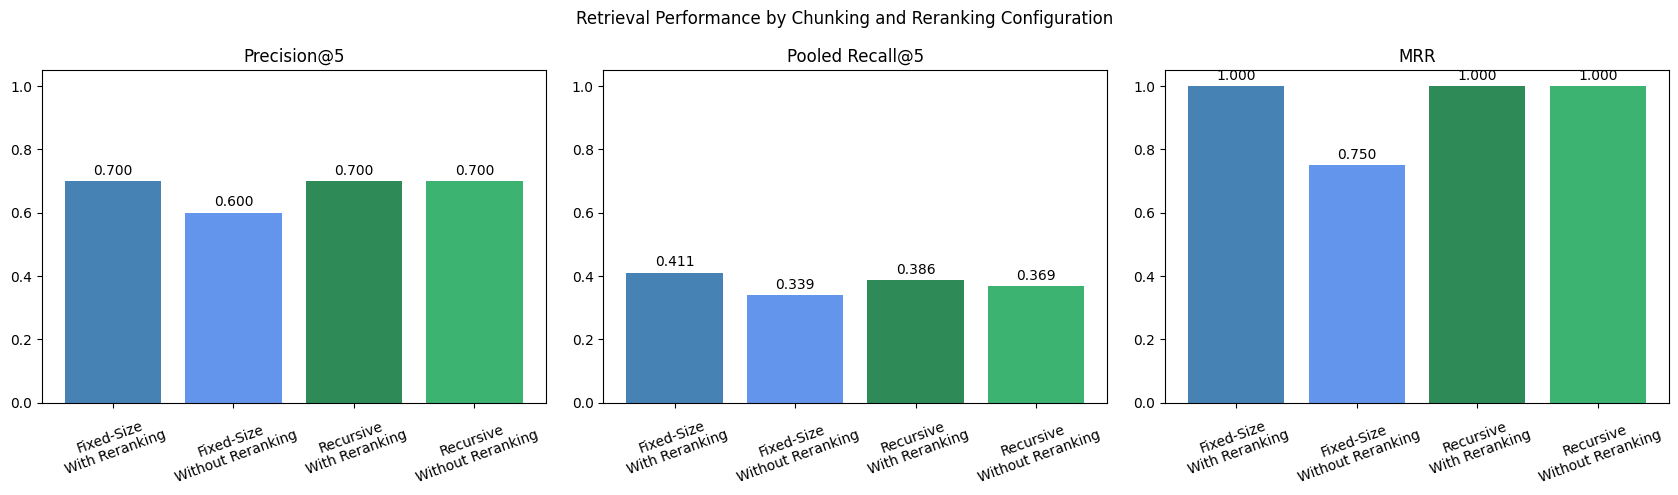

In [25]:
import matplotlib.pyplot as plt

plot_metrics_df = (
    aggregate_metrics_df.copy()
)

plot_metrics_df["Configuration"] = (
    plot_metrics_df["Strategy"]
    + "\n"
    + plot_metrics_df["Approach"]
)

metrics_to_plot = [
    "Precision@5",
    "Pooled Recall@5",
    "MRR"
]

figure, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

for axis, metric_name in zip(
    axes,
    metrics_to_plot
):
    axis.bar(
        plot_metrics_df["Configuration"],
        plot_metrics_df[metric_name],
        color=[
            "steelblue",
            "cornflowerblue",
            "seagreen",
            "mediumseagreen"
        ]
    )

    axis.set_title(metric_name)
    axis.set_ylim(0, 1.05)
    axis.tick_params(
        axis="x",
        rotation=20
    )

    for index, metric_value in enumerate(
        plot_metrics_df[metric_name]
    ):
        axis.text(
            index,
            metric_value + 0.02,
            f"{metric_value:.3f}",
            ha="center"
        )

plt.suptitle(
    "Retrieval Performance by Chunking "
    "and Reranking Configuration"
)

plt.tight_layout()
plt.show()

### 6.3 Retrieval Evaluation Findings

#### Effect of Reranking

Across both chunking strategies and both evaluation queries, reranking improved the average retrieval results:

| Metric | Without Reranking | With Reranking |
|---|---:|---:|
| Precision@5 | 0.6500 | 0.7000 |
| Pooled Recall@5 | 0.3543 | 0.3985 |
| MRR | 0.8750 | 1.0000 |

Reranking increased Precision@5 by 0.05 and pooled Recall@5 by approximately 0.0442. MRR increased from 0.875 to 1.000, indicating that reranking consistently placed a relevant passage at rank 1.

However, reranking did not improve every individual query. For Q2 with recursive chunking, Precision@5 decreased from 0.80 to 0.60. This demonstrates that a cross-encoder can improve average retrieval performance without improving every query.

#### Effect of Chunking Strategy

The average results across both ranking conditions were:

| Metric | Fixed-Size | Recursive |
|---|---:|---:|
| Precision@5 | 0.6500 | 0.7000 |
| Pooled Recall@5 | 0.3750 | 0.3778 |
| MRR | 0.8750 | 1.0000 |

Recursive chunking achieved higher average Precision@5 and MRR and a slightly higher pooled Recall@5. The improvement may result from recursive chunking preserving more meaningful text boundaries.

The best pooled Recall@5 was achieved by fixed-size chunking with reranking, at 0.4107. Therefore, recursive chunking performed better overall, but fixed-size chunking with reranking produced the highest recall for this evaluation set.

#### Evaluation Limitation

Recall was calculated using the manually judged top-20 candidate pool rather than every chunk in the complete database. It is therefore reported as pooled Recall@5.

The evaluation contains two queries from one research paper. The results demonstrate the required comparisons, but a larger and more diverse query set would provide stronger evidence of general performance.

### 6.4 Quantitative Evaluation of Conversational Memory

To isolate the effect of conversational memory, the fixed-size chunking strategy is held constant.

The intended information need is:

“How do additive models help in high-dimensional problems?”

Two retrieval conditions are compared:

- Without memory: “How do they help in high-dimensional problems?”
- With memory: “How do additive models help in high-dimensional problems?”

The top 10 results from both conditions are pooled. Each unique passage is judged once based on whether it helps answer the intended information need.

Precision@5, pooled Recall@5, and reciprocal rank are then calculated for both conditions.

In [26]:
import pandas as pd
import numpy as np

MEMORY_EVALUATION_POOL_K = 10

INTENDED_MEMORY_QUERY = (
    "How do additive models help "
    "in high-dimensional problems?"
)

without_memory_candidates = pd.DataFrame(
    retrieve_from_collection(
        query_id="Memory_Q",
        query_text=follow_up_query,
        collection=fixed_collection,
        strategy="Fixed-Size",
        top_k=MEMORY_EVALUATION_POOL_K
    )
).rename(
    columns={
        "rank": "rank_without_memory"
    }
)

with_memory_candidates = pd.DataFrame(
    retrieve_from_collection(
        query_id="Memory_Q",
        query_text=rewritten_follow_up_query,
        collection=fixed_collection,
        strategy="Fixed-Size",
        top_k=MEMORY_EVALUATION_POOL_K
    )
).rename(
    columns={
        "rank": "rank_with_memory"
    }
)

without_memory_ranks = (
    without_memory_candidates[
        ["chunk_id", "rank_without_memory"]
    ]
)

with_memory_ranks = (
    with_memory_candidates[
        ["chunk_id", "rank_with_memory"]
    ]
)

memory_rank_pool_df = (
    without_memory_ranks.merge(
        with_memory_ranks,
        on="chunk_id",
        how="outer"
    )
)

memory_passage_details_df = (
    pd.concat(
        [
            without_memory_candidates[
                [
                    "chunk_id",
                    "document_id",
                    "chunk_text"
                ]
            ],
            with_memory_candidates[
                [
                    "chunk_id",
                    "document_id",
                    "chunk_text"
                ]
            ]
        ],
        ignore_index=True
    )
    .drop_duplicates(
        subset=["chunk_id"]
    )
)

memory_judgment_base_df = (
    memory_rank_pool_df.merge(
        memory_passage_details_df,
        on="chunk_id",
        how="left",
        validate="one_to_one"
    )
)

memory_judgment_base_df.insert(
    0,
    "intended_query",
    INTENDED_MEMORY_QUERY
)

memory_judgment_base_df[
    "best_available_rank"
] = (
    memory_judgment_base_df[
        [
            "rank_without_memory",
            "rank_with_memory"
        ]
    ].min(axis=1)
)

memory_judgment_base_df = (
    memory_judgment_base_df.sort_values(
        [
            "best_available_rank",
            "chunk_id"
        ]
    )
    .drop(
        columns=["best_available_rank"]
    )
    .reset_index(drop=True)
)

MEMORY_JUDGMENT_FILE = (
    EVALUATION_DIRECTORY
    / "memory_relevance_judgments.csv"
)

if MEMORY_JUDGMENT_FILE.exists():
    previous_memory_labels_df = pd.read_csv(
        MEMORY_JUDGMENT_FILE
    )

    previous_memory_labels_df = (
        previous_memory_labels_df[
            [
                "chunk_id",
                "relevance",
                "review_notes"
            ]
        ]
    )

    memory_judgments_df = (
        memory_judgment_base_df.merge(
            previous_memory_labels_df,
            on="chunk_id",
            how="left",
            validate="one_to_one"
        )
    )

    print(
        "Existing memory labels found "
        "and preserved."
    )

else:
    memory_judgments_df = (
        memory_judgment_base_df.copy()
    )

    memory_judgments_df["relevance"] = pd.NA
    memory_judgments_df["review_notes"] = ""

    print(
        "A new memory judgment file "
        "was created."
    )

memory_judgments_df.to_csv(
    MEMORY_JUDGMENT_FILE,
    index=False
)

print("=" * 75)
print("MEMORY EVALUATION CANDIDATE POOL")
print("=" * 75)

print(
    "Without-memory candidates:",
    len(without_memory_candidates)
)

print(
    "With-memory candidates:",
    len(with_memory_candidates)
)

print(
    "Unique pooled passages:",
    len(memory_judgments_df)
)

print(
    "Already reviewed:",
    memory_judgments_df[
        "relevance"
    ].notna().sum()
)

print(
    "Remaining:",
    memory_judgments_df[
        "relevance"
    ].isna().sum()
)

print("\nSaved to:")
print(MEMORY_JUDGMENT_FILE)

A new memory judgment file was created.
MEMORY EVALUATION CANDIDATE POOL
Without-memory candidates: 10
With-memory candidates: 10
Unique pooled passages: 17
Already reviewed: 0
Remaining: 17

Saved to:
/content/drive/MyDrive/DATA266_HW10_CLEAN/evaluation/memory_relevance_judgments.csv


### Memory Relevance Criteria

Each pooled passage is judged against the intended information need:

“How do additive models help in high-dimensional problems?”

A passage is relevant if it explains one or more of the following:

- reduced susceptibility to the curse of dimensionality;
- improved high-dimensional learning or convergence rates;
- capacity bounds that do not grow with dimension;
- advantages of additive kernels in high-dimensional settings.

A passage is not relevant if it merely discusses additive models, kernels, formulas, or another subject without explaining their high-dimensional benefit.

In [27]:
import pandas as pd
import ipywidgets as widgets

from IPython.display import display, clear_output


memory_review_df = pd.read_csv(
    MEMORY_JUDGMENT_FILE
)

memory_review_df["relevance"] = pd.to_numeric(
    memory_review_df["relevance"],
    errors="coerce"
)

current_memory_index = [None]

memory_progress_display = widgets.HTML()
memory_passage_display = widgets.Output()

memory_relevant_button = widgets.Button(
    description="Relevant (1)",
    button_style="success"
)

memory_irrelevant_button = widgets.Button(
    description="Not Relevant (0)",
    button_style="danger"
)

memory_skip_button = widgets.Button(
    description="Skip",
    button_style="warning"
)

memory_previous_button = widgets.Button(
    description="Previous",
    button_style=""
)


def save_memory_reviews():
    memory_review_df.to_csv(
        MEMORY_JUDGMENT_FILE,
        index=False
    )


def find_next_unreviewed_memory(
    start_index=0
):
    total_rows = len(memory_review_df)

    for index in range(
        start_index,
        total_rows
    ):
        if pd.isna(
            memory_review_df.loc[
                index,
                "relevance"
            ]
        ):
            return index

    for index in range(0, start_index):
        if pd.isna(
            memory_review_df.loc[
                index,
                "relevance"
            ]
        ):
            return index

    return None


def format_optional_rank(rank_value):
    if pd.isna(rank_value):
        return "Not retrieved in top 10"

    return int(rank_value)


def show_memory_passage():
    reviewed_count = memory_review_df[
        "relevance"
    ].notna().sum()

    total_count = len(memory_review_df)

    memory_progress_display.value = (
        f"<b>Reviewed:</b> "
        f"{reviewed_count}/{total_count}"
        f"&nbsp;&nbsp;"
        f"<b>Remaining:</b> "
        f"{total_count - reviewed_count}"
    )

    with memory_passage_display:
        clear_output(wait=True)

        index = current_memory_index[0]

        if index is None:
            print("=" * 75)
            print(
                "ALL MEMORY PASSAGES REVIEWED"
            )
            print("=" * 75)
            print(
                "Continue to the memory metric cell."
            )
            return

        row = memory_review_df.iloc[index]

        print("=" * 75)
        print(
            f"MEMORY PASSAGE {index + 1} "
            f"OF {total_count}"
        )
        print("=" * 75)

        print(
            "Intended question:",
            row["intended_query"]
        )

        print(
            "Without-memory rank:",
            format_optional_rank(
                row["rank_without_memory"]
            )
        )

        print(
            "With-memory rank:",
            format_optional_rank(
                row["rank_with_memory"]
            )
        )

        print(
            "Document:",
            row["document_id"]
        )

        print(
            "Chunk:",
            row["chunk_id"]
        )

        print(
            "Current label:",
            row["relevance"]
        )

        print("\nPASSAGE")
        print("-" * 75)
        print(row["chunk_text"])
        print("-" * 75)


def record_memory_label(label):
    index = current_memory_index[0]

    if index is None:
        return

    memory_review_df.loc[
        index,
        "relevance"
    ] = label

    save_memory_reviews()

    current_memory_index[0] = (
        find_next_unreviewed_memory(
            index + 1
        )
    )

    show_memory_passage()


def mark_memory_relevant(button):
    record_memory_label(1)


def mark_memory_irrelevant(button):
    record_memory_label(0)


def skip_memory_passage(button):
    index = current_memory_index[0]

    if index is not None:
        current_memory_index[0] = (
            find_next_unreviewed_memory(
                index + 1
            )
        )

    show_memory_passage()


def show_previous_memory_passage(button):
    index = current_memory_index[0]

    if index is None:
        index = len(memory_review_df)

    current_memory_index[0] = max(
        0,
        index - 1
    )

    show_memory_passage()


memory_relevant_button.on_click(
    mark_memory_relevant
)

memory_irrelevant_button.on_click(
    mark_memory_irrelevant
)

memory_skip_button.on_click(
    skip_memory_passage
)

memory_previous_button.on_click(
    show_previous_memory_passage
)

current_memory_index[0] = (
    find_next_unreviewed_memory(0)
)

display(
    widgets.VBox([
        memory_progress_display,
        memory_passage_display,
        widgets.HBox([
            memory_relevant_button,
            memory_irrelevant_button,
            memory_skip_button,
            memory_previous_button
        ])
    ])
)

show_memory_passage()

### 6.5 Conversational Memory Metrics

The top-five rankings from the without-memory and with-memory conditions are evaluated against the same pooled relevance judgments.

Using the same pooled passage set ensures that changes in Precision@5, pooled Recall@5, and reciprocal rank are caused by query contextualization rather than different relevance definitions.

In [28]:
import pandas as pd
import numpy as np

MEMORY_METRIC_K = 5

completed_memory_judgments_df = pd.read_csv(
    MEMORY_JUDGMENT_FILE
)

completed_memory_judgments_df[
    "relevance"
] = pd.to_numeric(
    completed_memory_judgments_df[
        "relevance"
    ],
    errors="coerce"
)

assert completed_memory_judgments_df[
    "relevance"
].notna().all()

assert completed_memory_judgments_df[
    "relevance"
].isin([0, 1]).all()

total_relevant_memory_passages = int(
    completed_memory_judgments_df[
        "relevance"
    ].sum()
)

memory_condition_configuration = [
    (
        "Without Memory",
        "rank_without_memory"
    ),
    (
        "With Memory",
        "rank_with_memory"
    )
]

memory_metric_records = []

for condition_name, rank_column in (
    memory_condition_configuration
):
    ranked_condition_df = (
        completed_memory_judgments_df[
            completed_memory_judgments_df[
                rank_column
            ].notna()
        ]
        .sort_values(rank_column)
        .copy()
    )

    ranked_labels = (
        ranked_condition_df[
            "relevance"
        ].astype(int).to_numpy()
    )

    top_k_labels = ranked_labels[
        :MEMORY_METRIC_K
    ]

    precision_at_5 = (
        top_k_labels.sum()
        / MEMORY_METRIC_K
    )

    pooled_recall_at_5 = (
        top_k_labels.sum()
        / total_relevant_memory_passages
        if total_relevant_memory_passages > 0
        else 0.0
    )

    relevant_positions = np.flatnonzero(
        ranked_labels == 1
    )

    reciprocal_rank = (
        1.0 / (
            relevant_positions[0] + 1
        )
        if len(relevant_positions) > 0
        else 0.0
    )

    memory_metric_records.append({
        "Memory Condition": condition_name,
        "Precision@5": float(
            precision_at_5
        ),
        "Pooled Recall@5": float(
            pooled_recall_at_5
        ),
        "Reciprocal Rank": float(
            reciprocal_rank
        ),
        "Relevant in Top 5": int(
            top_k_labels.sum()
        ),
        "Relevant in Pooled Set": (
            total_relevant_memory_passages
        )
    })


memory_metrics_df = pd.DataFrame(
    memory_metric_records
)

print("=" * 80)
print("CONVERSATIONAL MEMORY EVALUATION")
print("=" * 80)

print(
    "Unique judged passages:",
    len(completed_memory_judgments_df)
)

print(
    "Relevant passages in pooled set:",
    total_relevant_memory_passages
)

print("\nWITHOUT VERSUS WITH MEMORY")
print("-" * 80)

display(
    memory_metrics_df.round(4)
)

CONVERSATIONAL MEMORY EVALUATION
Unique judged passages: 17
Relevant passages in pooled set: 5

WITHOUT VERSUS WITH MEMORY
--------------------------------------------------------------------------------


,Memory Condition,Precision@5,Pooled Recall@5,Reciprocal Rank,Relevant in Top 5,Relevant in Pooled Set
0,Without Memory,0.4,0.4,0.5,2,5
1,With Memory,0.8,0.8,1.0,4,5


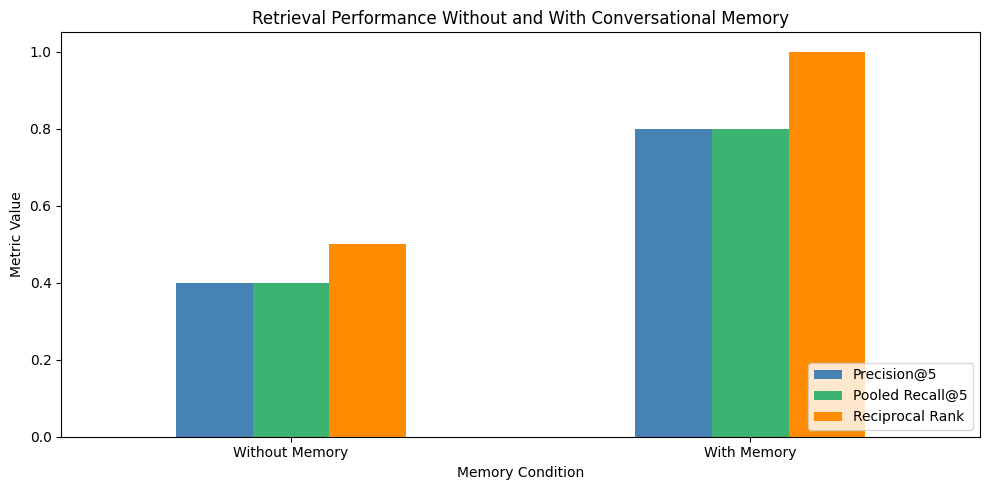

In [29]:
import matplotlib.pyplot as plt

memory_plot_df = (
    memory_metrics_df.set_index(
        "Memory Condition"
    )[
        [
            "Precision@5",
            "Pooled Recall@5",
            "Reciprocal Rank"
        ]
    ]
)

memory_plot_df.plot(
    kind="bar",
    figsize=(10, 5),
    color=[
        "steelblue",
        "mediumseagreen",
        "darkorange"
    ]
)

plt.title(
    "Retrieval Performance Without "
    "and With Conversational Memory"
)

plt.xlabel("Memory Condition")
plt.ylabel("Metric Value")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 6.6 Conversational Memory Findings

Conversational memory substantially improved retrieval for the dependent follow-up question.

| Metric | Without Memory | With Memory |
|---|---:|---:|
| Precision@5 | 0.4000 | 0.8000 |
| Pooled Recall@5 | 0.4000 | 0.8000 |
| Reciprocal Rank | 0.5000 | 1.0000 |
| Relevant Passages in Top 5 | 2 | 4 |

Without memory, the ambiguous pronoun “they” caused the retriever to return unrelated passages about geometry, image analysis, physical simulations, and other subjects.

With memory, the query was rewritten to mention additive models explicitly. This increased the number of relevant top-five passages from two to four.

Precision@5 and pooled Recall@5 both doubled from 0.40 to 0.80. Reciprocal rank increased from 0.50 to 1.00, meaning that the first relevant passage moved from rank 2 to rank 1.

These results demonstrate that even a simple conversational-memory mechanism can substantially improve retrieval when a follow-up question depends on an earlier turn.

## Final Findings and Conclusion

This notebook investigated three methods for improving retrieval in a RAG pipeline: chunking strategy, cross-encoder reranking, and conversational memory.

### 1. Chunking Comparison

Fixed-size chunking produced 4,536 chunks with a mean length of 991.55 characters. Recursive chunking produced 4,660 chunks with a mean length of 873.91 characters.

Fixed-size chunks were more uniform, while recursive chunks preserved more natural punctuation and word boundaries but produced 36 short passages under 200 characters.

Across the evaluated retrieval configurations, recursive chunking performed slightly better overall:

| Metric | Fixed-Size | Recursive |
|---|---:|---:|
| Precision@5 | 0.6500 | 0.7000 |
| Pooled Recall@5 | 0.3750 | 0.3778 |
| MRR | 0.8750 | 1.0000 |

Recursive chunking therefore provided the strongest overall retrieval quality, although fixed-size chunking with reranking achieved the highest individual pooled Recall@5 of 0.4107.

### 2. Reranking Comparison

The overall results before and after cross-encoder reranking were:

| Metric | Without Reranking | With Reranking |
|---|---:|---:|
| Precision@5 | 0.6500 | 0.7000 |
| Pooled Recall@5 | 0.3543 | 0.3985 |
| MRR | 0.8750 | 1.0000 |

Reranking improved all three average metrics. It was particularly beneficial for fixed-size chunking, where MRR increased from 0.75 to 1.00.

Reranking did not improve every individual query. For Q2 with recursive chunking, Precision@5 decreased from 0.80 to 0.60. This shows that cross-encoder reranking should be evaluated across multiple queries rather than assumed to improve every result.

### 3. Conversational Memory Comparison

The dependent follow-up question showed a substantial benefit from query contextualization:

| Metric | Without Memory | With Memory |
|---|---:|---:|
| Precision@5 | 0.4000 | 0.8000 |
| Pooled Recall@5 | 0.4000 | 0.8000 |
| Reciprocal Rank | 0.5000 | 1.0000 |

Conversational memory resolved the ambiguous pronoun in the follow-up question and doubled both Precision@5 and pooled Recall@5.

### Conclusion

The experiment demonstrates that RAG retrieval can be improved at multiple stages:

- Recursive chunking can preserve more meaningful textual boundaries and achieved the strongest average retrieval performance.
- Cross-encoder reranking improved average Precision@5, pooled Recall@5, and MRR.
- Conversational memory produced the largest improvement for an ambiguous dependent follow-up query.

The strongest retrieval configuration depends on the evaluation objective. Recursive chunking performed best overall, while fixed-size chunking with reranking achieved the highest pooled Recall@5 in this evaluation.

### Limitations

The main retrieval evaluation used two questions derived from one research paper. A larger query set covering more documents and research areas would provide stronger evidence of general performance.

Recall@5 was calculated using manually judged top-20 candidate pools rather than every relevant chunk in the complete collection. It is therefore reported as pooled Recall@5.

The conversational-memory mechanism performs simple topic extraction and pronoun replacement. A production system would require more general reference resolution and support for longer conversation histories.

In [30]:
print("=" * 75)
print("FINAL ASSIGNMENT REQUIREMENT VERIFICATION")
print("=" * 75)

verification_checks = {
    "Required dataset used": (
        DATASET_NAME
        == "ccdv/arxiv-summarization"
    ),
    "Document configuration used": (
        DATASET_CONFIG == "document"
    ),
    "Training split used": (
        DATASET_SPLIT == "train"
    ),
    "Exactly 100 documents loaded": (
        len(processed_df) == 100
    ),
    "Two chunking strategies implemented": (
        len(fixed_chunks_df) > 0
        and len(recursive_chunks_df) > 0
    ),
    "Fixed chunks indexed in ChromaDB": (
        fixed_collection.count()
        == len(fixed_chunks_df)
    ),
    "Recursive chunks indexed in ChromaDB": (
        recursive_collection.count()
        == len(recursive_chunks_df)
    ),
    "At least two sample queries used": (
        len(SAMPLE_QUERIES) >= 2
    ),
    "Baseline retrieval completed": (
        len(baseline_results_df) == 20
    ),
    "Same queries reranked": (
        len(reranked_results_df) == 20
    ),
    "Conversational memory implemented": (
        rewritten_follow_up_query
        != follow_up_query
    ),
    "Retrieval judgments completed": (
        completed_judgments_df[
            "relevance"
        ].notna().all()
    ),
    "Precision, recall, and MRR calculated": (
        {
            "Precision@5",
            "Pooled Recall@5",
            "MRR"
        }.issubset(
            aggregate_metrics_df.columns
        )
    ),
    "Chunking strategies compared": (
        len(
            chunking_quality_comparison_df
        ) == 2
    ),
    "Reranking conditions compared": (
        len(
            reranking_comparison_metrics_df
        ) == 2
    ),
    "Memory judgments completed": (
        completed_memory_judgments_df[
            "relevance"
        ].notna().all()
    ),
    "Memory conditions compared": (
        len(memory_metrics_df) == 2
    )
}

all_requirements_passed = True

for requirement, passed in (
    verification_checks.items()
):
    status = "PASS" if passed else "FAIL"
    print(f"{status:4s} | {requirement}")

    if not passed:
        all_requirements_passed = False

print("\n" + "=" * 75)

if all_requirements_passed:
    print(
        "STATUS: ALL IMPLEMENTED "
        "REQUIREMENT CHECKS PASSED"
    )
else:
    print(
        "STATUS: ONE OR MORE "
        "REQUIREMENT CHECKS FAILED"
    )

print("=" * 75)

FINAL ASSIGNMENT REQUIREMENT VERIFICATION
PASS | Required dataset used
PASS | Document configuration used
PASS | Training split used
PASS | Exactly 100 documents loaded
PASS | Two chunking strategies implemented
PASS | Fixed chunks indexed in ChromaDB
PASS | Recursive chunks indexed in ChromaDB
PASS | At least two sample queries used
PASS | Baseline retrieval completed
PASS | Same queries reranked
PASS | Conversational memory implemented
PASS | Retrieval judgments completed
PASS | Precision, recall, and MRR calculated
PASS | Chunking strategies compared
PASS | Reranking conditions compared
PASS | Memory judgments completed
PASS | Memory conditions compared

STATUS: ALL IMPLEMENTED REQUIREMENT CHECKS PASSED


In [31]:
from pathlib import Path
import pandas as pd
import sys
import torch

ARTIFACT_DIRECTORY = Path(
    "/content/drive/MyDrive/DATA266_HW10_CLEAN/artifacts"
)

ARTIFACT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True
)

# -----------------------------
# Run log
# -----------------------------

run_log_df = pd.DataFrame([
    {
        "Stage": "Environment",
        "Status": "PASS",
        "Details": (
            f"Python {sys.version.split()[0]}, "
            f"PyTorch {torch.__version__}, "
            f"device={DEVICE}"
        )
    },
    {
        "Stage": "Dataset loading",
        "Status": "PASS",
        "Details": (
            f"{len(processed_df)} documents; "
            f"configuration={DATASET_CONFIG}; "
            f"split={DATASET_SPLIT}"
        )
    },
    {
        "Stage": "Preprocessing",
        "Status": "PASS",
        "Details": (
            "100 documents, 0 empty articles, "
            "0 duplicate articles"
        )
    },
    {
        "Stage": "Fixed-size chunking",
        "Status": "PASS",
        "Details": f"{len(fixed_chunks_df)} chunks"
    },
    {
        "Stage": "Recursive chunking",
        "Status": "PASS",
        "Details": f"{len(recursive_chunks_df)} chunks"
    },
    {
        "Stage": "Embedding generation",
        "Status": "PASS",
        "Details": (
            f"{len(fixed_embeddings) + len(recursive_embeddings)} "
            f"embeddings; dimension={embedding_dimension}"
        )
    },
    {
        "Stage": "ChromaDB indexing",
        "Status": "PASS",
        "Details": (
            f"{fixed_collection.count() + recursive_collection.count()} "
            "records indexed"
        )
    },
    {
        "Stage": "Baseline retrieval",
        "Status": "PASS",
        "Details": f"{len(baseline_results_df)} final results"
    },
    {
        "Stage": "Cross-encoder reranking",
        "Status": "PASS",
        "Details": (
            f"{len(reranked_candidates_df)} candidates; "
            f"{len(reranked_results_df)} final results"
        )
    },
    {
        "Stage": "Retrieval judgments",
        "Status": "PASS",
        "Details": (
            f"{len(completed_judgments_df)}/"
            f"{len(completed_judgments_df)} completed"
        )
    },
    {
        "Stage": "Memory judgments",
        "Status": "PASS",
        "Details": (
            f"{len(completed_memory_judgments_df)}/"
            f"{len(completed_memory_judgments_df)} completed"
        )
    },
    {
        "Stage": "Final verification",
        "Status": (
            "PASS"
            if all_requirements_passed
            else "FAIL"
        ),
        "Details": (
            "All implemented requirement checks passed"
            if all_requirements_passed
            else "One or more checks failed"
        )
    }
])

run_log_df.to_csv(
    ARTIFACT_DIRECTORY / "run_log.csv",
    index=False
)

# -----------------------------
# Metric exports
# -----------------------------

per_query_metrics_df.to_csv(
    ARTIFACT_DIRECTORY
    / "per_query_retrieval_metrics.csv",
    index=False
)

aggregate_metrics_df.to_csv(
    ARTIFACT_DIRECTORY
    / "aggregate_retrieval_metrics.csv",
    index=False
)

reranking_comparison_metrics_df.to_csv(
    ARTIFACT_DIRECTORY
    / "reranking_comparison_metrics.csv",
    index=False
)

chunking_quality_comparison_df.to_csv(
    ARTIFACT_DIRECTORY
    / "chunking_comparison_metrics.csv",
    index=False
)

memory_metrics_df.to_csv(
    ARTIFACT_DIRECTORY
    / "memory_comparison_metrics.csv",
    index=False
)

# -----------------------------
# Failure-analysis export
# -----------------------------

failure_analysis_df = pd.DataFrame([
    {
        "Failure": "Reranking regression",
        "Evidence": (
            "Recursive Q2 Precision@5 decreased "
            "from 0.80 to 0.60"
        ),
        "Possible Improvement": (
            "Tune candidate depth, combine retrieval "
            "and reranker scores, or test another reranker"
        )
    },
    {
        "Failure": "Ambiguous follow-up without memory",
        "Evidence": (
            "Precision@5 and pooled Recall@5 were 0.40"
        ),
        "Possible Improvement": (
            "Use coreference-aware or LLM-based "
            "query rewriting"
        )
    },
    {
        "Failure": "Very short recursive chunks",
        "Evidence": (
            "36 recursive chunks were under 200 "
            "characters; minimum length was 9"
        ),
        "Possible Improvement": (
            "Merge short fragments with adjacent chunks"
        )
    },
    {
        "Failure": "Limited evaluation coverage",
        "Evidence": (
            "Two primary evaluation queries came "
            "from one research article"
        ),
        "Possible Improvement": (
            "Evaluate more queries from diverse documents"
        )
    },
    {
        "Failure": "Candidate-pool limitation",
        "Evidence": (
            "Reranker only saw the top 20 embedding results"
        ),
        "Possible Improvement": (
            "Use hybrid retrieval and a larger candidate pool"
        )
    }
])

failure_analysis_df.to_csv(
    ARTIFACT_DIRECTORY / "failure_analysis.csv",
    index=False
)

print("=" * 75)
print("SUBMISSION ARTIFACT EXPORT")
print("=" * 75)

display(run_log_df)

print("\nFiles exported to:")
print(ARTIFACT_DIRECTORY)

for exported_file in sorted(
    ARTIFACT_DIRECTORY.glob("*.csv")
):
    print("-", exported_file.name)

print("\nARTIFACT EXPORT COMPLETED")

SUBMISSION ARTIFACT EXPORT


,Stage,Status,Details
0,Environment,PASS,"Python 3.13.16, PyTorch 2.14.1+cu130, device=cuda"
1,Dataset loading,PASS,100 documents; configuration=document; split=t...
2,Preprocessing,PASS,"100 documents, 0 empty articles, 0 duplicate a..."
3,Fixed-size chunking,PASS,4536 chunks
4,Recursive chunking,PASS,4660 chunks
5,Embedding generation,PASS,9196 embeddings; dimension=384
6,ChromaDB indexing,PASS,9196 records indexed
7,Baseline retrieval,PASS,20 final results
8,Cross-encoder reranking,PASS,80 candidates; 20 final results
9,Retrieval judgments,PASS,80/80 completed



Files exported to:
/content/drive/MyDrive/DATA266_HW10_CLEAN/artifacts
- aggregate_retrieval_metrics.csv
- chunking_comparison_metrics.csv
- failure_analysis.csv
- memory_comparison_metrics.csv
- per_query_retrieval_metrics.csv
- reranking_comparison_metrics.csv
- run_log.csv

ARTIFACT EXPORT COMPLETED
